# SignSage — Final Kaggle Research & Training Notebook

This notebook is the **reference ML/research artifact** for SignSage.

It is designed to run the current SignSage pipeline end-to-end on Kaggle with the available GPU, while keeping the large iSign pose archive remote and loading only the pose members required by the selected experiment.

The notebook produces two kinds of outputs:

1. **Model artifacts** — trained checkpoints, tokenizer/vocabulary information, and model configuration.
2. **Project knowledge repository** — a SQLite database plus a JSON manifest containing dataset facts, split information, preprocessing configuration, experiment settings, training history, evaluation metrics, latency measurements, round-trip results, and artifact locations.

The knowledge repository is **not a RAG knowledge base** and does not replace the trained models. It is the structured, reproducible record of how the SignSage models were built and evaluated. It is intended to be copied from Kaggle into the project repository later and consumed by the backend for model/version metadata and research transparency.

> **Important:** A bounded Kaggle run is an execution/validation run, not automatically a thesis-quality final result. The notebook explicitly records the run configuration so a larger run can be distinguished from a smoke/bounded run.


## 0. Prerequisites

### Kaggle mode

The notebook is optimized for Kaggle GPU execution.

The large iSign pose archive is **not fully extracted into Kaggle storage**. Instead, the notebook uses the Hugging Face-backed multipart ZIP64 reader already implemented below and fetches only the pose members required by the selected samples.

Expected remote resources:

- `iSign_v1.1.csv`
- multipart iSign pose archive:
  - `iSign-poses_v1.1_part_aa`
  - `iSign-poses_v1.1_part_ab`
  - `iSign-poses_v1.1_part_ac`
  - `iSign-poses_v1.1_part_ad`
- Kaggle Secret: `HF_TOKEN`, with read access to `Exploration-Lab/iSign`

### Local mode

The same notebook can still run on the local storage machine when `SIGNSAGE_DATA_DIR` points to the iSign root directory containing:

```text
iSign/
├── iSign_v1.1.csv
└── poses/
    └── iSign-poses_v1.1/
        └── *.pose
```

### Execution order

Run the notebook **top to bottom**. The notebook is deliberately organized as:

```text
Environment
    ↓
Dataset verification
    ↓
Data audit
    ↓
Leak-safe video-level split
    ↓
Tokenizer / vocabulary
    ↓
Pose normalization + cache
    ↓
DataLoader smoke check
    ↓
Sign → Text models
    ↓
Sign → Text evaluation
    ↓
Text → Sign baselines / generator
    ↓
Text → Sign evaluation
    ↓
Visualization + round-trip
    ↓
Latency
    ↓
Knowledge repository finalization
    ↓
Research GO / NO-GO report
    ↓
Export manifest
```


## 0a. Performance & memory strategy

The earlier optimization was appropriate for the old local HDD setup, but it had one fatal problem for Kaggle: **prewarming the cache over the entire dataset defeats the purpose of using the remote archive and can make the notebook look frozen.**

This version changes that behavior:

- **No automatic full-dataset prewarm.** Pose files are fetched only when a selected train/validation/test example actually needs them.
- **Kaggle never reconstructs the 228 GB archive.** It opens the four remote ZIP parts as one virtual concatenated file and uses ZIP64 metadata to locate individual members. Python's `zipfile` supports ZIP64 but not multipart archives directly, so the virtual file is the important compatibility layer.
- **On-disk normalized cache remains enabled.** Once a pose is fetched and normalized, later epochs reuse the small local `.npy` cache.
- **Visible progress remains enabled.** Training and cache access show progress instead of appearing to hang.
- **GPU is used when available.** Kaggle's T4 runtime is selected automatically by PyTorch; the model is intentionally small enough that forcing two-GPU `DataParallel` would add overhead without solving the actual remote-I/O bottleneck.
- **The first Kaggle run is a bounded validation experiment.** Increase the sample limits only after this run completes cleanly.


In [1]:
# SignSage configuration + environment detection
# The cell is intentionally self-contained so the notebook can be moved between
# Kaggle and the local storage machine without editing filesystem code elsewhere.

import os
import gc
import io
import json
import random
import time
import warnings
import zipfile
from pathlib import Path
from collections import Counter
from functools import lru_cache
from contextlib import nullcontext

from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

IS_KAGGLE = Path("/kaggle").exists() or bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
DATA_MODE = "kaggle" if IS_KAGGLE else "local"

# -------- RUN CONTROL --------
# KAGGLE is intentionally bounded. It is not a claim that 2,000 examples are enough
# for the final thesis result; it is the reproducible first GPU validation pass.
RUN_MODE = "kaggle" if IS_KAGGLE else "smoke"  # kaggle | smoke | full

if RUN_MODE == "smoke":
    TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 300, 60, 60
    N_EPOCHS_GRU, N_EPOCHS_TRANSFORMER, N_EPOCHS_POSE = 4, 5, 5
elif RUN_MODE == "kaggle":
    # SCALE-UP (see DECISIONS.md): the first bounded run (2000/300/300) was a pipeline
    # validation pass, not a result -- both GRU and the Text-to-Pose generator hit their
    # best validation loss at epoch 1 and got worse afterward, which is a data-scale
    # symptom (overfitting within a single epoch), not something more epochs alone fixes.
    # This run raises TRAIN_LIMIT ~5x. GRU epoch count is left unchanged since it is a
    # throwaway sanity baseline that already overfit past epoch 1; Transformer/Text-to-Pose
    # get a modest epoch bump since compute is cheap relative to the remote pose-fetch cost
    # that actually dominates wall-clock time here (see BATCH_SIZE note below).
    TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 10000, 1500, 1500
    N_EPOCHS_GRU, N_EPOCHS_TRANSFORMER, N_EPOCHS_POSE = 5, 8, 8
else:
    TRAIN_LIMIT = VAL_LIMIT = TEST_LIMIT = None
    N_EPOCHS_GRU, N_EPOCHS_TRANSFORMER, N_EPOCHS_POSE = 20, 25, 25

try:
    import psutil
    def check_memory():
        mem = psutil.virtual_memory()
        swap = psutil.swap_memory()
        print(f"RAM: {mem.used/1024**3:.1f} GB / {mem.total/1024**3:.1f} GB ({mem.percent}%)")
        print(f"Swap: {swap.used/1024**3:.1f} GB / {swap.total/1024**3:.1f} GB ({swap.percent}%)")
        if swap.percent > 30:
            print("⚠️ HIGH SWAP — reduce sample limits before continuing.")
        return mem, swap
    check_memory()
except ImportError:
    def check_memory():
        return None, None

MAX_TOKENS = 40
MAX_FRAMES = 160
POSE_OUTPUT_FRAMES = 60
# Bumped from 20: this eval is pure CPU DTW over already-cached poses (negligible
# extra cost), and 20 test examples was too small a sample for the Text->Pose
# generative-vs-retrieval comparison to be trustworthy.
DTW_EVAL_N = 200
# Bumped from 16: these are small models (d_model=192) on a T4 with plenty of headroom;
# a larger batch reduces optimizer-step overhead now that TRAIN_LIMIT is 5x larger. Fetch
# time (network-bound, per-UID) is unaffected by this -- it is the actual bottleneck below.
BATCH_SIZE = 32 if DEVICE.type == "cuda" else 8
NUM_WORKERS = 0
CACHE_SIZE = 8
# Defined once here (not inside the retrieval-baseline cell) so the
# reproducibility-config cell can record it correctly regardless of
# cell execution/re-run order, and so local/Kaggle runs share one
# consistent retrieval-pool cap.
RETRIEVAL_MAX_SAMPLES = 3000
GRAD_ACCUM_STEPS = 1 if DEVICE.type == "cuda" else 4
USE_POSE_DISK_CACHE = True
# BUG FIX: this used to check `DEVICE.type == "cpu"`, so on a Kaggle GPU
# (DEVICE.type == "cuda") autocast never actually engaged -- the notebook's own
# "GPU is used when available" performance strategy was a no-op in practice.
# T4 (Turing) has no fast native bf16 tensor-core path, so fp16 is the right
# mixed-precision dtype on Kaggle's recommended GPU T4x2, not bf16.
USE_AMP = DEVICE.type == "cuda"          # fp16 autocast + GradScaler on CUDA
USE_BF16_AUTOCAST_CPU = False             # optional CPU bf16 autocast; off by default (rarely a win)
PREWARM_CACHE = False  # NEVER prewarm the complete Kaggle dataset.
USE_LLM_GLOSS = False  # Optional Groq gloss upgrade for the Text->Sign generator (Section 12).
                        # Off by default: the naive heuristic is the reproducible benchmark
                        # (see DECISIONS.md); flipping this makes one network call per training/
                        # val/test row (with a per-row fallback to the naive heuristic on any
                        # API failure), trading determinism and speed for a possibly better gloss.

def autocast_ctx():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    if USE_BF16_AUTOCAST_CPU and DEVICE.type == "cpu":
        try:
            return torch.autocast(device_type="cpu", dtype=torch.bfloat16)
        except Exception:
            return nullcontext()
    return nullcontext()

# GradScaler(enabled=False) is a correct, cheap no-op, so the same
# scaler.scale(...)/scaler.step(...)/scaler.update() pattern below works
# unchanged on CPU (smoke/local runs) and on CUDA (Kaggle) without branching
# every training loop on device type.
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except TypeError:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def maybe_check_memory():
    try:
        check_memory()
    except Exception:
        pass

# Local path is used only in local mode. Kaggle stores only CSV/cache data in working.
if DATA_MODE == "local":
    DATA_DIR = Path(os.environ.get("SIGNSAGE_DATA_DIR", "")).expanduser()
    if not str(DATA_DIR):
        raise RuntimeError("SIGNSAGE_DATA_DIR is not set. Example: /home/adrija/SignSageData/iSign")
else:
    DATA_DIR = Path("/kaggle/working/signsage_data")
    DATA_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "iSign_v1.1.csv"
POSE_DIR = DATA_DIR / "poses" / "iSign-poses_v1.1"

print("Python:", os.sys.executable)
print("Device:", DEVICE)
print("GPU count:", torch.cuda.device_count())
if DEVICE.type == "cuda":
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
print("Data mode:", DATA_MODE)
print("Run mode:", RUN_MODE)
print("Data dir:", DATA_DIR)
print("CSV:", CSV_PATH)
print("Pose dir:", POSE_DIR)
print("Mixed precision (AMP):", USE_AMP)


RAM: 1.0 GB / 31.3 GB (4.7%)
Swap: 0.0 GB / 0.0 GB (0.0%)
Python: /usr/bin/python3
Device: cuda
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Data mode: kaggle
Run mode: kaggle
Data dir: /kaggle/working/signsage_data
CSV: /kaggle/working/signsage_data/iSign_v1.1.csv
Pose dir: /kaggle/working/signsage_data/poses/iSign-poses_v1.1
Mixed precision (AMP): True


In [2]:
# 0b. Project knowledge repository (SQLite + JSON)
#
# Kaggle is the experiment workspace. This repository is the structured record
# that will later be copied into the main SignSage project for backend use.
#
# SQLite = queryable historical/research record
# JSON    = portable run manifest / configuration snapshot

import sqlite3
from pathlib import Path
from datetime import datetime, timezone

OUTPUT_DIR = Path("/kaggle/working/signsage_outputs") if DATA_MODE == "kaggle" else Path.cwd() / "signsage_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_DIR = OUTPUT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

KNOWLEDGE_DB_PATH = OUTPUT_DIR / "signsage_knowledge.db"
KNOWLEDGE_JSON_PATH = OUTPUT_DIR / "signsage_knowledge_manifest.json"

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_STARTED_AT = datetime.now(timezone.utc).isoformat()

def _sql_connect():
    conn = sqlite3.connect(KNOWLEDGE_DB_PATH)
    conn.execute("PRAGMA foreign_keys = ON")
    return conn

def init_knowledge_repository():
    conn = _sql_connect()
    conn.executescript("""
    CREATE TABLE IF NOT EXISTS runs (
        run_id TEXT PRIMARY KEY,
        started_at TEXT NOT NULL,
        completed_at TEXT,
        data_mode TEXT NOT NULL,
        run_mode TEXT NOT NULL,
        device TEXT NOT NULL,
        gpu_count INTEGER NOT NULL,
        seed INTEGER NOT NULL
    );

    CREATE TABLE IF NOT EXISTS dataset (
        run_id TEXT PRIMARY KEY,
        dataset_name TEXT NOT NULL,
        csv_path TEXT,
        csv_rows INTEGER,
        unique_video_ids INTEGER,
        pose_source TEXT,
        selected_rows INTEGER,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );

    CREATE TABLE IF NOT EXISTS splits (
        run_id TEXT PRIMARY KEY,
        train_rows INTEGER,
        val_rows INTEGER,
        test_rows INTEGER,
        train_videos INTEGER,
        val_videos INTEGER,
        test_videos INTEGER,
        leakage_free INTEGER,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );

    CREATE TABLE IF NOT EXISTS experiments (
        experiment_id INTEGER PRIMARY KEY AUTOINCREMENT,
        run_id TEXT NOT NULL,
        name TEXT NOT NULL,
        family TEXT NOT NULL,
        input_features TEXT,
        epochs INTEGER,
        batch_size INTEGER,
        learning_rate REAL,
        weight_decay REAL,
        checkpoint_path TEXT,
        best_validation_loss REAL,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );

    CREATE TABLE IF NOT EXISTS metrics (
        metric_id INTEGER PRIMARY KEY AUTOINCREMENT,
        run_id TEXT NOT NULL,
        experiment_name TEXT NOT NULL,
        metric_name TEXT NOT NULL,
        metric_value REAL,
        split_name TEXT,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );

    CREATE TABLE IF NOT EXISTS artifacts (
        artifact_id INTEGER PRIMARY KEY AUTOINCREMENT,
        run_id TEXT NOT NULL,
        artifact_name TEXT NOT NULL,
        artifact_type TEXT NOT NULL,
        path TEXT NOT NULL,
        description TEXT,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );

    CREATE TABLE IF NOT EXISTS observations (
        observation_id INTEGER PRIMARY KEY AUTOINCREMENT,
        run_id TEXT NOT NULL,
        key TEXT NOT NULL,
        value TEXT,
        FOREIGN KEY(run_id) REFERENCES runs(run_id)
    );
    """)
    conn.execute(
        """INSERT OR REPLACE INTO runs
           (run_id, started_at, completed_at, data_mode, run_mode, device, gpu_count, seed)
           VALUES (?, ?, ?, ?, ?, ?, ?, ?)""",
        (RUN_ID, RUN_STARTED_AT, None, DATA_MODE, RUN_MODE, str(DEVICE),
         int(torch.cuda.device_count()), int(SEED)),
    )
    conn.commit()
    conn.close()

def knowledge_insert(table, columns, values, delete_keys=None):
    """Insert one row, optionally deleting any existing row(s) that match
    `delete_keys` first. Tables whose primary key is `run_id` (dataset,
    splits) don't need this -- INSERT OR REPLACE already keys off it -- but
    tables with an autoincrement id (experiments) have no natural
    uniqueness, so without an explicit delete, re-running a training cell
    silently appends a duplicate row instead of replacing it."""
    conn = _sql_connect()
    if delete_keys:
        where_clause = " AND ".join(f"{col} IS ?" for col in delete_keys)
        conn.execute(f"DELETE FROM {table} WHERE {where_clause}", tuple(delete_keys.values()))
    placeholders = ", ".join(["?"] * len(values))
    conn.execute(
        f"INSERT OR REPLACE INTO {table} ({', '.join(columns)}) VALUES ({placeholders})",
        tuple(values),
    )
    conn.commit()
    conn.close()

def knowledge_metric(experiment_name, metric_name, value, split_name=None):
    conn = _sql_connect()
    # Idempotent: replace the matching (run, experiment, metric, split) row
    # instead of appending a duplicate on re-run. `IS ?` (not `= ?`) so this
    # also matches correctly when split_name is NULL.
    conn.execute(
        """DELETE FROM metrics
           WHERE run_id = ? AND experiment_name = ? AND metric_name = ? AND split_name IS ?""",
        (RUN_ID, experiment_name, metric_name, split_name),
    )
    conn.execute(
        """INSERT INTO metrics
           (run_id, experiment_name, metric_name, metric_value, split_name)
           VALUES (?, ?, ?, ?, ?)""",
        (RUN_ID, experiment_name, metric_name, float(value), split_name),
    )
    conn.commit()
    conn.close()

def knowledge_artifact(name, artifact_type, path, description=""):
    conn = _sql_connect()
    # Idempotent: one row per (run_id, artifact_name); re-running a cell
    # updates the existing artifact record instead of duplicating it.
    conn.execute(
        "DELETE FROM artifacts WHERE run_id = ? AND artifact_name = ?",
        (RUN_ID, name),
    )
    conn.execute(
        """INSERT INTO artifacts
           (run_id, artifact_name, artifact_type, path, description)
           VALUES (?, ?, ?, ?, ?)""",
        (RUN_ID, name, artifact_type, str(path), description),
    )
    conn.commit()
    conn.close()

def knowledge_observation(key, value):
    # Deliberately append-only (unlike the writers above): observations such
    # as "go_no_go" are log-style notes, not a single fact per key, so a
    # re-run recording another entry is the correct behavior here.
    conn = _sql_connect()
    conn.execute(
        "INSERT INTO observations (run_id, key, value) VALUES (?, ?, ?)",
        (RUN_ID, str(key), json.dumps(value, default=str)),
    )
    conn.commit()
    conn.close()

init_knowledge_repository()

print("Knowledge DB :", KNOWLEDGE_DB_PATH)
print("Knowledge JSON:", KNOWLEDGE_JSON_PATH)
print("Run ID       :", RUN_ID)


Knowledge DB : /kaggle/working/signsage_outputs/signsage_knowledge.db
Knowledge JSON: /kaggle/working/signsage_outputs/signsage_knowledge_manifest.json
Run ID       : 20260903T134623Z


In [3]:
# Kaggle-only dependency installation.
# Kaggle's default GPU image does not include pose-format, jiwer, sacrebleu,
# or rouge-score, and its bundled huggingface_hub can be too old for
# `hf_hub_download(..., local_dir=...)` to behave reliably. Installing these
# here -- before anything below imports them -- is what actually lets the
# rest of this notebook run top-to-bottom on a fresh Kaggle kernel; without
# it, the very next cell's `from pose_format import Pose` raises
# ModuleNotFoundError before the dataset is even touched.
#
# Local-machine venvs are expected to already have these installed (see
# Section 0 / the commented-out install line in the original local notebook),
# so this deliberately does nothing outside Kaggle mode.
if IS_KAGGLE:
    import subprocess
    import sys as _sys

    _KAGGLE_ONLY_PACKAGES = [
        "pose-format",
        "jiwer",
        "sacrebleu",
        "rouge-score",
        "huggingface_hub>=0.24.0",
        "requests",  # used directly by the remote ZIP64 backend (cell below);
                     # declared explicitly rather than assumed from the base image.
    ]
    print("Kaggle mode: installing packages not present in the default image:")
    print(" ", ", ".join(_KAGGLE_ONLY_PACKAGES))
    subprocess.run(
        [_sys.executable, "-m", "pip", "install", "-q", "--no-input", *_KAGGLE_ONLY_PACKAGES],
        check=True,
    )
    print("Done. (Safe to re-run this cell; pip install is idempotent.)")
else:
    print("Local mode: skipping Kaggle-only package installation "
          "(the local venv is expected to already have these -- see Section 0).")


Kaggle mode: installing packages not present in the default image:
  pose-format, jiwer, sacrebleu, rouge-score, huggingface_hub>=0.24.0, requests
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.5/117.5 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 76.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 58.2 MB/s eta 0:00:00
Done. (Safe to re-run this cell; pip install is idempotent.)


In [4]:
# 1. Verify the dataset before touching the models.

# Guard: this cell depends on Section 0's configuration + environment detection cell
# (defines DATA_MODE, DEVICE, IS_KAGGLE, etc.) having already run in this kernel. If this
# cell is run on its own in a fresh/restarted session, DATA_MODE won't exist yet, which
# otherwise surfaces as a bare `NameError: name 'DATA_MODE' is not defined` pointing at an
# unrelated line below. This turns that into an actionable message instead.
if "DATA_MODE" not in globals():
    raise RuntimeError(
        "DATA_MODE is not defined in this kernel. Section 0's configuration + environment "
        "detection cell (the first code cell in the notebook) has not run yet in this "
        "session -- likely because this cell was run on its own in a fresh/restarted kernel.\n\n"
        "Fix: Restart the kernel and use Run All, or manually run every cell above this one, "
        "in order, before re-running this one. See PHASES.md's 'First-run sequence' for the "
        "intended run order."
    )

if DATA_MODE == "local":
    assert CSV_PATH.is_file(), f"Missing CSV: {CSV_PATH}"
    assert POSE_DIR.is_dir(), f"Missing pose directory: {POSE_DIR}"
    pose_files = sorted(POSE_DIR.glob("*.pose"))
else:
    # Kaggle: download only the 9.81 MB CSV. The ~228 GB pose archive stays remote.
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import hf_hub_download

    try:
        HF_TOKEN = os.environ.get("HF_TOKEN")
        if not HF_TOKEN:
            HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as exc:
        raise RuntimeError("Kaggle mode needs a Kaggle Secret named HF_TOKEN.") from exc

    if not HF_TOKEN:
        raise RuntimeError("HF_TOKEN is empty. Add your Hugging Face read token as a Kaggle Secret named HF_TOKEN.")

    csv_downloaded = hf_hub_download(
        repo_id="Exploration-Lab/iSign",
        filename="iSign_v1.1.csv",
        repo_type="dataset",
        token=HF_TOKEN,
        local_dir=str(DATA_DIR),
    )
    CSV_PATH = Path(csv_downloaded)
    pose_files = []  # RemotePoseStore will verify individual members later.

df = pd.read_csv(CSV_PATH)
assert {"uid", "text"}.issubset(df.columns), f"Expected uid/text columns, found: {df.columns.tolist()}"

df["uid"] = df["uid"].astype(str)
df["text"] = df["text"].fillna("").astype(str)
df[["video_id", "seq"]] = df["uid"].str.rsplit("-", n=1, expand=True)
df["n_words"] = df["text"].str.split().str.len()

print(f"CSV rows: {len(df):,}")
print(f"CSV columns: {df.columns.tolist()}")
print(f"Unique video_ids: {df['video_id'].nunique():,}")
if DATA_MODE == "local":
    print(f"Pose files: {len(pose_files):,}")
    print("OK: local CSV row count matches local pose-file count." if len(pose_files) == len(df) else "WARNING: local CSV and pose-file counts differ.")
else:
    print("Pose files: remote multipart ZIP — no full extraction attempted.")

print("\nSample UID mappings:")
for _, r in df.head(5).iterrows():
    print(" ", r["uid"])


iSign_v1.1.csv: 0.00B [00:00, ?B/s]

CSV rows: 127,237
CSV columns: ['uid', 'text', 'video_id', 'seq', 'n_words']
Unique video_ids: 6,058
Pose files: remote multipart ZIP — no full extraction attempted.

Sample UID mappings:
  1782bea75c7d-1
  1782bea75c7d-2
  1782bea75c7d-3
  1782bea75c7d-4
  1782bea75c7d-5


In [5]:
# 1a. Record dataset facts in the knowledge repository.
pose_source = (
    "local UID-level .pose files"
    if DATA_MODE == "local"
    else "remote multipart ZIP64 archive on Hugging Face; lazy member reads"
)
selected_rows = len(df)

knowledge_insert(
    "dataset",
    ["run_id", "dataset_name", "csv_path", "csv_rows", "unique_video_ids", "pose_source", "selected_rows"],
    [RUN_ID, "iSign v1.1", str(CSV_PATH), int(len(df)), int(df["video_id"].nunique()), pose_source, int(selected_rows)],
)
knowledge_observation("dataset_columns", df.columns.tolist())
knowledge_observation("text_empty_rows", int((df["text"].str.strip() == "").sum()))

print("Dataset metadata recorded in SQLite.")


Dataset metadata recorded in SQLite.


In [6]:
# Kaggle remote ZIP64 backend
# The four iSign pose files are consecutive byte ranges of ONE ZIP archive.
# This backend presents them as one seekable virtual file so Python zipfile can
# read the ZIP64 central directory and then fetch only requested members.
# Reads are explicitly bounded to both part and HTTP-chunk boundaries so no bytes
# are skipped when zipfile asks for a range that crosses a cached chunk.

if DATA_MODE == "kaggle":
    import re
    import requests
    from huggingface_hub import hf_hub_url

    REMOTE_PARTS = [
        "iSign-poses_v1.1_part_aa",
        "iSign-poses_v1.1_part_ab",
        "iSign-poses_v1.1_part_ac",
        "iSign-poses_v1.1_part_ad",
    ]
    REMOTE_CHUNK_SIZE = 4 * 1024 * 1024
    REMOTE_TIMEOUT = 60

    class RemoteConcatFile(io.RawIOBase):
        def __init__(self, urls, sizes, token, chunk_size=REMOTE_CHUNK_SIZE):
            super().__init__()
            self.urls = urls
            self.sizes = sizes
            self.starts = np.cumsum([0] + sizes[:-1]).tolist()
            self.total_size = int(sum(sizes))
            self.pos = 0
            self.token = token
            self.chunk_size = int(chunk_size)
            self.session = requests.Session()
            self.session.headers.update({
                "Authorization": f"Bearer {token}",
                "User-Agent": "SignSage-Kaggle/1.0",
            })
            self.cache = {}
            # Caches the final (post-redirect) CDN URL per part so repeated chunk
            # fetches skip the huggingface.co auth+redirect hop. Cleared and
            # re-resolved automatically if a cached link ever expires (see _fetch).
            self.resolved = {}

        def readable(self):
            return True

        def seekable(self):
            return True

        def tell(self):
            return self.pos

        def seek(self, offset, whence=os.SEEK_SET):
            if whence == os.SEEK_SET:
                new = offset
            elif whence == os.SEEK_CUR:
                new = self.pos + offset
            elif whence == os.SEEK_END:
                new = self.total_size + offset
            else:
                raise ValueError("invalid whence")
            if new < 0:
                raise ValueError("negative seek position")
            self.pos = min(int(new), self.total_size)
            return self.pos

        def _part_for(self, pos):
            idx = int(np.searchsorted(self.starts, pos, side="right") - 1)
            idx = max(0, min(idx, len(self.urls) - 1))
            return idx, pos - self.starts[idx]

        def _fetch(self, part_idx, local_start, n):
            key = (part_idx, (local_start // self.chunk_size) * self.chunk_size)
            if key not in self.cache:
                chunk_start = key[1]
                chunk_end = min(
                    self.sizes[part_idx] - 1,
                    chunk_start + self.chunk_size - 1,
                )
                headers = {"Range": f"bytes={chunk_start}-{chunk_end}"}
                request_url = self.resolved.get(part_idx, self.urls[part_idx])
                r = self.session.get(
                    request_url,
                    headers=headers,
                    timeout=REMOTE_TIMEOUT,
                    allow_redirects=True,
                )
                if r.status_code != 206 and request_url != self.urls[part_idx]:
                    # The cached CDN URL likely expired (presigned links are
                    # time-limited, and a Kaggle session can run for hours) --
                    # drop it and re-resolve from the origin before giving up.
                    self.resolved.pop(part_idx, None)
                    r = self.session.get(
                        self.urls[part_idx],
                        headers=headers,
                        timeout=REMOTE_TIMEOUT,
                        allow_redirects=True,
                    )
                if r.status_code != 206:
                    raise RuntimeError(
                        f"Range request failed for part {part_idx}: HTTP {r.status_code}. "
                        "The Kaggle session must have Internet enabled and the HF token must have dataset access."
                    )
                # Remember the resolved URL (post-redirect) for the next chunk of
                # this part, so we don't pay the origin round trip again.
                self.resolved[part_idx] = r.url

                cr = r.headers.get("Content-Range", "")
                # IMPORTANT: use single-backslash regex escapes here. A raw string
                # containing \d would look for a literal '\d' and reject valid
                # responses such as: bytes 25275138048-25275140831/25275140832.
                match = re.fullmatch(r"bytes (\d+)-(\d+)/(\d+)", cr.strip())
                if not match:
                    raise RuntimeError(f"Invalid Content-Range from HF response: {cr!r}")

                returned_start, returned_end, returned_total = map(int, match.groups())
                if returned_total != self.sizes[part_idx]:
                    raise RuntimeError(
                        f"HF reported part {part_idx} total size {returned_total}, "
                        f"but the size probe reported {self.sizes[part_idx]}."
                    )

                # Some HTTP/CDN layers may legally return a range that covers the
                # requested interval rather than byte-for-byte matching it. Accept
                # that as long as the requested bytes are fully present.
                if not (returned_start <= chunk_start and chunk_end <= returned_end):
                    raise RuntimeError(
                        f"HF returned byte range {returned_start}-{returned_end}; "
                        f"requested {chunk_start}-{chunk_end}."
                    )

                expected_response_len = returned_end - returned_start + 1
                if len(r.content) != expected_response_len:
                    raise RuntimeError(
                        f"Incomplete range response for part {part_idx}: "
                        f"Content-Range says {expected_response_len} bytes, "
                        f"but received {len(r.content)}."
                    )

                # Cache the actual returned range together with its starting offset.
                self.cache[key] = (returned_start, r.content)
                if len(self.cache) > 32:
                    self.cache.pop(next(iter(self.cache)))

            returned_start, content = self.cache[key]
            offset = local_start - returned_start
            piece = content[offset:offset + n]
            if len(piece) != n:
                raise RuntimeError(
                    f"Remote range backend returned {len(piece)} bytes; expected {n}."
                )
            return piece

        def read(self, n=-1):
            if self.pos >= self.total_size:
                return b""
            if n is None or n < 0:
                n = self.total_size - self.pos
            n = min(int(n), self.total_size - self.pos)
            out = bytearray()
            remaining = n
            while remaining:
                part_idx, local = self._part_for(self.pos)
                bytes_to_part_end = self.sizes[part_idx] - local
                bytes_to_chunk_end = self.chunk_size - (local % self.chunk_size)
                take = min(remaining, bytes_to_part_end, bytes_to_chunk_end)
                piece = self._fetch(part_idx, local, take)
                out.extend(piece)
                self.pos += take
                remaining -= take
            return bytes(out)

    def _remote_size(url):
        # A one-byte Range request gives the authoritative total size via Content-Range
        # without downloading a huge file.
        r = requests.get(
            url,
            headers={
                "Authorization": f"Bearer {HF_TOKEN}",
                "Range": "bytes=0-0",
                "User-Agent": "SignSage-Kaggle/1.0",
            },
            timeout=REMOTE_TIMEOUT,
            allow_redirects=True,
        )
        if r.status_code != 206:
            raise RuntimeError(f"Could not probe remote part size: HTTP {r.status_code}")
        cr = r.headers.get("Content-Range", "")
        total = cr.rsplit("/", 1)[-1] if "/" in cr else ""
        if not total.isdigit():
            raise RuntimeError(f"Could not parse total size from Content-Range: {cr!r}")
        return int(total)

    remote_urls = [
        hf_hub_url("Exploration-Lab/iSign", f, repo_type="dataset")
        for f in REMOTE_PARTS
    ]
    remote_sizes = []
    for name, url in zip(REMOTE_PARTS, remote_urls):
        size = _remote_size(url)
        remote_sizes.append(size)
        print(f"{name}: {size / 1024**3:.2f} GiB")

    remote_file = RemoteConcatFile(remote_urls, remote_sizes, HF_TOKEN)
    remote_zip = zipfile.ZipFile(remote_file, mode="r", allowZip64=True)
    remote_names = set(remote_zip.namelist())
    print(f"Remote ZIP opened: {len(remote_names):,} members")

    # The member-path layout inside this archive is an assumption, not a verified
    # fact: RemotePoseStore below only tries "iSign-poses_v1.1/{uid}.pose" and
    # "{uid}.pose". Printing a few real member names here means a different prefix
    # or nesting depth is visible immediately, on the very first Kaggle run --
    # instead of surfacing later as a FileNotFoundError on every single UID, after
    # the split/tokenizer/cache cells have already run.
    print("Sample members:", sorted(remote_names)[:5])

    class RemotePoseStore:
        def __init__(self, zf, names):
            self.zf = zf
            self.names = names

        def _candidate(self, uid):
            candidates = (
                f"iSign-poses_v1.1/{uid}.pose",
                f"{uid}.pose",
            )
            for name in candidates:
                if name in self.names:
                    return name
            raise FileNotFoundError(
                f"UID not found in remote iSign pose archive: {uid}"
            )

        def read_member_bytes(self, uid):
            with self.zf.open(self._candidate(uid), "r") as f:
                return f.read()

    remote_pose_store = RemotePoseStore(remote_zip, remote_names)
    print("Remote pose backend ready — individual .pose members will be fetched lazily.")
else:
    remote_pose_store = None


iSign-poses_v1.1_part_aa: 45.00 GiB
iSign-poses_v1.1_part_ab: 45.00 GiB
iSign-poses_v1.1_part_ac: 45.00 GiB
iSign-poses_v1.1_part_ad: 23.54 GiB
Remote ZIP opened: 127,238 members
Sample members: ['iSign-poses_v1.1/', 'iSign-poses_v1.1/-02o_0vVwzI--0.pose', 'iSign-poses_v1.1/-02o_0vVwzI--1.pose', 'iSign-poses_v1.1/-02o_0vVwzI--10.pose', 'iSign-poses_v1.1/-02o_0vVwzI--11.pose']
Remote pose backend ready — individual .pose members will be fetched lazily.


## 2. Data audit

The audit is deliberately before training. A model cannot repair systematic text/pose misalignment.

The local dataset inspection already established that the `.pose` archive uses **row/UID-level files**, not `<video_id>.pose`. Therefore every CSV row is resolved through its complete UID.

In [7]:
from pose_format import Pose

def read_pose_bytes_for_uid(uid):
    if DATA_MODE == "local":
        path = POSE_DIR / f"{uid}.pose"
        if not path.is_file():
            raise FileNotFoundError(path)
        return path.read_bytes()
    return remote_pose_store.read_member_bytes(uid)

# Inspect a few actual pose files through the active backend.
sample_uids = df.head(5)["uid"].tolist()
for uid in sample_uids:
    p = Pose.read(read_pose_bytes_for_uid(uid))
    data = np.asarray(np.ma.filled(p.body.data, 0.0))
    conf = np.asarray(np.ma.filled(p.body.confidence, 0.0))
    print(f"{uid}.pose: shape={data.shape}, mean_confidence={conf.mean():.3f}")

example_pose = Pose.read(read_pose_bytes_for_uid(sample_uids[0]))
example_data = np.asarray(np.ma.filled(example_pose.body.data, 0.0))
TOTAL_KEYPOINTS = example_data.shape[2]
print("\nVerified pose shape:", example_data.shape)
print("Keypoints:", TOTAL_KEYPOINTS)


1782bea75c7d-1.pose: shape=(113, 1, 576, 3), mean_confidence=0.965
1782bea75c7d-2.pose: shape=(104, 1, 576, 3), mean_confidence=0.960
1782bea75c7d-3.pose: shape=(196, 1, 576, 3), mean_confidence=0.961
1782bea75c7d-4.pose: shape=(78, 1, 576, 3), mean_confidence=0.965
1782bea75c7d-5.pose: shape=(124, 1, 576, 3), mean_confidence=0.963

Verified pose shape: (113, 1, 576, 3)
Keypoints: 576


In [8]:
# Manual text audit — deterministic and reproducible.
audit_sample = df.sample(min(15, len(df)), random_state=SEED)
for _, row in audit_sample.iterrows():
    print(f"{row['uid']} | {row['text']}")

# Timing metadata audit. Current local CSV has no timing columns, so we do NOT invent them.
time_like_cols = [c for c in df.columns if any(k in c.lower() for k in ("start", "end", "time"))]
print("\nPossible timing columns:", time_like_cols)
if not time_like_cols:
    print("No per-segment timing columns found. This is acceptable here because the local archive has one pose file per UID/row.")


r5jQBIcELLI--20 | He said, ‘CMs come and go. I am not hungry for power. I am ready to resign if my party does not want me.”
006faf1f7c93-14 | New words learnt from the poem.
koyLu-2VMOM--10 | She then filed for divorce in November 2020.
fVYU48ftZaI--35 | Whoa, Rs 3000 per month?
5Dc552hY1Kk--32 | Deaf drivers have been involved in fewer car accidents than the average driver.
dxg-dX-GYhc--6 | Very surprising! However
3odTMYaauMc--35 | India was storing up its stocks to prepare for any COVID emergency.
IykCj1JGO5A--251 | speech they will ask government to pass
Im-RbrxB4Ho--10 | He lives in New Jersey, America
6Lb8PCw6vcc--62 | Let us begin by testing different food items to see if they contain carbohydrates.
L0T8bWEUpcE--0 | 13 months ago, the Shiv Sena party had decided that they will fight the elections alone.
C1yQj2MhtZE--25 | India has always said that problems between two countries will be resolved among themselves.
UZzXTTsTe_Q--31 | The Officials had told this to Defence minister R

In [9]:
# 3. Leak-safe split by video_id.
video_ids = np.array(df["video_id"].unique(), dtype=object)
rng = np.random.default_rng(SEED)
rng.shuffle(video_ids)

n_videos = len(video_ids)
train_cut = int(0.80 * n_videos)
val_cut = int(0.90 * n_videos)

train_ids = set(video_ids[:train_cut])
val_ids = set(video_ids[train_cut:val_cut])
test_ids = set(video_ids[val_cut:])

df_train_all = df[df["video_id"].isin(train_ids)].reset_index(drop=True)
df_val_all = df[df["video_id"].isin(val_ids)].reset_index(drop=True)
df_test_all = df[df["video_id"].isin(test_ids)].reset_index(drop=True)

def limit_frame(frame, limit):
    if limit is None or limit >= len(frame):
        return frame.copy().reset_index(drop=True)
    return frame.sample(limit, random_state=SEED).reset_index(drop=True)

df_train = limit_frame(df_train_all[df_train_all["n_words"] <= MAX_TOKENS - 2], TRAIN_LIMIT)
df_val = limit_frame(df_val_all[df_val_all["n_words"] <= MAX_TOKENS - 2], VAL_LIMIT)
df_test = limit_frame(df_test_all[df_test_all["n_words"] <= MAX_TOKENS - 2], TEST_LIMIT)

print(f"All split rows: train={len(df_train_all):,}, val={len(df_val_all):,}, test={len(df_test_all):,}")
print(f"Run rows:        train={len(df_train):,}, val={len(df_val):,}, test={len(df_test):,}")

assert set(df_train.video_id).isdisjoint(df_val.video_id)
assert set(df_train.video_id).isdisjoint(df_test.video_id)
assert set(df_val.video_id).isdisjoint(df_test.video_id)
print("No video_id leakage across train/val/test.")


All split rows: train=102,757, val=12,380, test=12,100
Run rows:        train=10,000, val=1,500, test=1,500
No video_id leakage across train/val/test.


In [10]:
# 3a. Record the video-level split in the knowledge repository.
train_videos = int(df_train["video_id"].nunique())
val_videos = int(df_val["video_id"].nunique())
test_videos = int(df_test["video_id"].nunique())

overlap_train_val = len(set(df_train["video_id"]) & set(df_val["video_id"]))
overlap_train_test = len(set(df_train["video_id"]) & set(df_test["video_id"]))
overlap_val_test = len(set(df_val["video_id"]) & set(df_test["video_id"]))
leakage_free = (overlap_train_val == overlap_train_test == overlap_val_test == 0)

knowledge_insert(
    "splits",
    ["run_id", "train_rows", "val_rows", "test_rows", "train_videos", "val_videos", "test_videos", "leakage_free"],
    [RUN_ID, len(df_train), len(df_val), len(df_test), train_videos, val_videos, test_videos, int(leakage_free)],
)
knowledge_observation("split_video_overlap", {
    "train_val": overlap_train_val,
    "train_test": overlap_train_test,
    "val_test": overlap_val_test,
})
print("Split metadata recorded. Leakage-free:", leakage_free)


Split metadata recorded. Leakage-free: True


## 4. Tokenizer

A simple whitespace tokenizer is retained for the core experiment so the notebook does not hide the translation problem behind a large pretrained language model.

The vocabulary is built from **training text only**. Unknown validation/test words map to `<unk>`.

In [11]:
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]

def build_vocab(texts):
    counter = Counter()
    for text in texts:
        counter.update(str(text).lower().split())
    vocab = {tok: i for i, tok in enumerate(SPECIALS)}
    for word, freq in counter.items():
        if freq >= 1 and word not in vocab:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(df_train["text"])
inv_vocab = {i: w for w, i in vocab.items()}
PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = [vocab[s] for s in SPECIALS]

def encode_text(text, max_len=MAX_TOKENS):
    words = str(text).lower().split()
    if max_len is not None:
        words = words[: max_len - 2]  # always leave room for BOS/EOS
    return [BOS_IDX] + [vocab.get(w, UNK_IDX) for w in words] + [EOS_IDX]

def decode_ids(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_IDX:
            break
        if idx not in (BOS_IDX, PAD_IDX):
            words.append(inv_vocab.get(idx, "<unk>"))
    return " ".join(words)

print("Vocabulary size:", len(vocab))

# Vocabulary is built from the training split only (by design -- see DATA_MODEL.md), so a
# small TRAIN_LIMIT (bounded Kaggle run) means a small vocab, which means val/test references
# get heavily masked to <unk> at eval time. This is worth surfacing explicitly: a model can't
# be faulted for failing to predict a word it was structurally never given the chance to learn.
def _unk_rate(frame):
    total = unk = 0
    for text in frame["text"]:
        for w in str(text).lower().split():
            total += 1
            if w not in vocab:
                unk += 1
    return (unk / total) if total else 0.0

val_unk_rate = _unk_rate(df_val)
test_unk_rate = _unk_rate(df_test)
print(f"<unk> word rate -- val: {val_unk_rate:.1%}, test: {test_unk_rate:.1%} "
      f"(vocab built from {len(df_train):,} training rows only)")
if max(val_unk_rate, test_unk_rate) > 0.15:
    print("NOTE: high <unk> rate at this scale is expected (see DATA_MODEL.md/PHASES.md) and "
          "will suppress WER/BLEU regardless of model quality -- don't read low scores here as "
          "purely a modeling failure without checking this number first.")
knowledge_observation("vocabulary_coverage", {
    "vocab_size": int(len(vocab)),
    "val_unk_rate": float(val_unk_rate),
    "test_unk_rate": float(test_unk_rate),
})


Vocabulary size: 17214
<unk> word rate -- val: 10.8%, test: 10.6% (vocab built from 10,000 training rows only)


## 5. Pose representation and face ablation

The actual pose header contains:

- `POSE_LANDMARKS`: 33
- `FACE_LANDMARKS`: 468
- `LEFT_HAND_LANDMARKS`: 21
- `RIGHT_HAND_LANDMARKS`: 21
- `POSE_WORLD_LANDMARKS`: 33

For SignSage's intended MediaPipe-style input, the main experiment uses the first **543 image-space landmarks** (pose + face + hands) and deliberately excludes the duplicated `POSE_WORLD_LANDMARKS` block.

The no-face ablation retains pose + both hands.

Sequences are normalized by a sequence-level body center and scale. This reduces dependence on camera translation/size while preserving temporal motion.

In [12]:
# Confirm component ranges from the real file rather than hardcoding the face indices blindly.
def get_component_ranges(pose):
    ranges = {}
    idx = 0
    for component in pose.header.components:
        n_points = len(component.points)
        ranges[str(component.name)] = (idx, idx + n_points)
        idx += n_points
    return ranges

component_ranges = get_component_ranges(example_pose)
print(component_ranges)

IMAGE_KEYPOINTS = list(range(543))
face_range = component_ranges.get("FACE_LANDMARKS")
assert face_range is not None, "FACE_LANDMARKS was not found; do not run the ablation until the pose header is understood."

keep_noface = [
    i for i in IMAGE_KEYPOINTS
    if not (face_range[0] <= i < face_range[1])
]

FULL_FEATURE_MASK = np.array([3*i + j for i in IMAGE_KEYPOINTS for j in range(3)], dtype=np.int64)
NOFACE_FEATURE_MASK = np.array([3*i + j for i in keep_noface for j in range(3)], dtype=np.int64)

print("Full keypoints/features:", len(IMAGE_KEYPOINTS), len(FULL_FEATURE_MASK))
print("No-face keypoints/features:", len(keep_noface), len(NOFACE_FEATURE_MASK))


{'POSE_LANDMARKS': (0, 33), 'FACE_LANDMARKS': (33, 501), 'LEFT_HAND_LANDMARKS': (501, 522), 'RIGHT_HAND_LANDMARKS': (522, 543), 'POSE_WORLD_LANDMARKS': (543, 576)}
Full keypoints/features: 543 1629
No-face keypoints/features: 75 225


### 5a. Disk-backed normalized-pose cache

The cache stores normalized pose arrays locally after their first access. In **Kaggle mode**, this is a small working-disk cache over a remote source; it is intentionally populated lazily rather than by scanning the entire archive.


In [13]:
# The normalized pose cache is regenerable scratch data, not a deliverable, so on
# Kaggle it deliberately does NOT live under DATA_DIR (/kaggle/working/...):
# /kaggle/working is committed as the notebook's saved output and counts against
# the 20 GB output limit, so a multi-GB cache there would bloat every saved version
# and compete with the checkpoints/reports that are actually meant to be downloaded.
# /kaggle/temp is session scratch on the same instance disk and is discarded when
# the session ends -- correct for this data, since every cached array can be
# rebuilt from the remote archive. Local mode keeps the cache next to the dataset,
# where persisting it across runs is the whole point.
CACHE_ROOT = Path("/kaggle/temp/signsage_cache") if DATA_MODE == "kaggle" else DATA_DIR / "cache"
POSE_CACHE_DIR = CACHE_ROOT / "normalized_v1"
POSE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Pose cache dir:", POSE_CACHE_DIR)

def pose_path_for_uid(uid):
    if DATA_MODE != "local":
        raise RuntimeError("pose_path_for_uid() is only valid in local mode; use read_pose_bytes_for_uid() in Kaggle mode.")
    path = POSE_DIR / f"{uid}.pose"
    if not path.is_file():
        raise FileNotFoundError(f"Missing UID-level pose file: {path}")
    return path

def _cache_path_for_uid(uid):
    return POSE_CACHE_DIR / f"{uid}.npy"

# Running counters so rare data-quality edge cases (missing hip landmarks, or a pose
# sequence with no frame having any spatial variance at all) are tallied across the
# whole run instead of only ever appearing as an unlabeled stderr warning. Reported
# in Section 17/19 below.
POSE_NORMALIZATION_STATS = {
    "total_sequences": 0,
    "bad_center_sequences": 0,
    "degenerate_scale_sequences": 0,
}

def normalize_pose_sequence(flat):
    """Root-center and scale one sequence; preserves frame-to-frame motion."""
    POSE_NORMALIZATION_STATS["total_sequences"] += 1
    x = flat.reshape(flat.shape[0], 543, 3).astype(np.float32)
    hip = x[:, [23, 24], :]
    center = hip.mean(axis=1, keepdims=True)
    bad_center = ~np.isfinite(center).all(axis=(1, 2))
    if bad_center.any():
        POSE_NORMALIZATION_STATS["bad_center_sequences"] += 1
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Mean of empty slice")
            center[bad_center] = np.nanmean(x[bad_center, :33, :], axis=1, keepdims=True)
    x = x - center
    body = x[:, :33, :]
    scale = np.nanstd(body.reshape(body.shape[0], -1), axis=1)
    valid_scale = scale[np.isfinite(scale) & (scale > 1e-6)]
    # BUG FIX: np.nanmedian on an empty array raises "Mean of empty slice" *unguarded* --
    # this used to leak into training-loop stderr (visible in the first Kaggle run).
    # A sequence hitting this path has NO frame with any real body-keypoint spread at all
    # (a fully static/degenerate capture), which is worth counting, not just silently
    # defaulting to scale=1.0 with no record of how often it happens.
    if valid_scale.size == 0:
        POSE_NORMALIZATION_STATS["degenerate_scale_sequences"] += 1
        scale = 1.0
    else:
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Mean of empty slice")
            scale = np.nanmedian(valid_scale)
        if not np.isfinite(scale) or scale <= 1e-6:
            POSE_NORMALIZATION_STATS["degenerate_scale_sequences"] += 1
            scale = 1.0
    x = x / float(scale)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    return x.reshape(x.shape[0], -1).astype(np.float32)

def resize_sequence(seq, target_len):
    src_len = seq.shape[0]
    if src_len <= 0:
        raise ValueError("Empty pose sequence")
    if src_len == target_len:
        return seq.astype(np.float32)
    if src_len > target_len:
        idx = np.linspace(0, src_len - 1, target_len)
        return seq[np.round(idx).astype(int)].astype(np.float32)
    out = np.zeros((target_len, seq.shape[1]), dtype=np.float32)
    out[:src_len] = seq
    return out

def _read_and_normalize_raw(uid):
    raw_bytes = read_pose_bytes_for_uid(uid)
    pose = Pose.read(raw_bytes)
    data = np.asarray(np.ma.filled(pose.body.data, 0.0), dtype=np.float32)
    if data.ndim != 4 or data.shape[1] < 1:
        raise ValueError(f"Unexpected pose tensor {data.shape} for {uid}")
    data = data[:, 0, :, :]
    data = data[:, :543, :]
    flat = data.reshape(data.shape[0], -1).astype(np.float32)
    return normalize_pose_sequence(flat)

@lru_cache(maxsize=CACHE_SIZE)
def _read_pose_file(uid):
    if USE_POSE_DISK_CACHE:
        cpath = _cache_path_for_uid(uid)
        if cpath.is_file():
            try:
                return np.load(cpath).astype(np.float32)
            except Exception:
                cpath.unlink(missing_ok=True)
    arr = _read_and_normalize_raw(uid)
    if USE_POSE_DISK_CACHE:
        tmp_path = _cache_path_for_uid(uid).with_name(_cache_path_for_uid(uid).name + ".tmp")
        with open(tmp_path, "wb") as f:
            np.save(f, arr.astype(np.float16))
        os.replace(tmp_path, _cache_path_for_uid(uid))
    return arr

def load_pose(row, feature_mask=FULL_FEATURE_MASK, max_frames=MAX_FRAMES):
    raw = _read_pose_file(row["uid"])
    raw = raw[:, feature_mask]
    true_len = min(len(raw), max_frames)
    processed = resize_sequence(raw, max_frames)
    return processed, true_len

for _, row in df_train.head(5).iterrows():
    if DATA_MODE == "local":
        p = pose_path_for_uid(row["uid"])
        print(row["uid"], "->", p.name)
    else:
        print(row["uid"], "-> remote ZIP member")
print("UID-to-pose alignment passed.")

if USE_POSE_DISK_CACHE:
    # Spot-check that downcasting the normalized cache to fp16 (to save disk)
    # doesn't meaningfully distort values relative to the fp32 array it was
    # computed from. `_read_pose_file` returns the fresh fp32 array on a
    # cache miss (not yet round-tripped), so the cache must be cleared and
    # re-read to actually exercise the on-disk fp16 path.
    print("\nSpot-checking fp16 disk-cache precision vs. fresh fp32 computation:")
    for _uid in df_train.head(3)["uid"].tolist():
        _fresh = _read_and_normalize_raw(_uid)
        _read_pose_file(_uid)          # populate the disk cache
        _read_pose_file.cache_clear()  # force the next call to read from disk, not memory
        _cached = _read_pose_file(_uid)
        _diff = float(np.max(np.abs(_fresh - _cached)))
        print(f"  {_uid}: max abs diff (fp32 fresh vs. fp16 disk round-trip) = {_diff:.6f}")
    print("Small diffs relative to the ~unit normalized-pose scale confirm fp16 caching is safe.\n")


Pose cache dir: /kaggle/temp/signsage_cache/normalized_v1
zuuFlJktQAA--178 -> remote ZIP member
IpRLdrFqxKk--182 -> remote ZIP member
CCwsuYLYemI--0 -> remote ZIP member
Xcr40XiJqFw--78 -> remote ZIP member
V6dMrT9oeHA--16 -> remote ZIP member
UID-to-pose alignment passed.

Spot-checking fp16 disk-cache precision vs. fresh fp32 computation:
  zuuFlJktQAA--178: max abs diff (fp32 fresh vs. fp16 disk round-trip) = 0.000977
  IpRLdrFqxKk--182: max abs diff (fp32 fresh vs. fp16 disk round-trip) = 0.000977
  CCwsuYLYemI--0: max abs diff (fp32 fresh vs. fp16 disk round-trip) = 0.000977
Small diffs relative to the ~unit normalized-pose scale confirm fp16 caching is safe.



**Before running a full pass**, a rough sanity check on free disk space for the new
cache (skip if `USE_POSE_DISK_CACHE = False`):


In [14]:
import shutil

def _estimate_full_cache_bytes(n_rows, avg_frames=150, n_landmarks=543, bytes_per_val=2):
    return n_rows * avg_frames * n_landmarks * 3 * bytes_per_val

if USE_POSE_DISK_CACHE:
    # BUG FIX: this used to check disk_usage(DATA_DIR), but the pose cache actually lives
    # at POSE_CACHE_DIR -- /kaggle/temp/... on Kaggle, DATA_DIR/cache locally -- which is a
    # different mount from DATA_DIR on Kaggle. Checking DATA_DIR told you nothing about the
    # disk that actually fills up as this cache grows.
    free_bytes = shutil.disk_usage(POSE_CACHE_DIR).free
    projected_rows = len(df) if RUN_MODE == "full" else sum(x for x in [TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT] if x)
    projected_bytes = _estimate_full_cache_bytes(projected_rows)
    print(f"Free space at {POSE_CACHE_DIR}: {free_bytes / 1024**3:.1f} GB")
    print(f"Rough cache estimate for this run: {projected_bytes / 1024**3:.2f} GB")
    if projected_bytes > 0.8 * free_bytes:
        print("WARNING: estimated cache is too large for the available disk. Reduce sample limits.")
else:
    print("USE_POSE_DISK_CACHE is False -- skipping disk-space check.")


Free space at /kaggle/temp/signsage_cache/normalized_v1: 1026.7 GB
Rough cache estimate for this run: 5.92 GB


### 5c. Pose cache warm-up

**Disabled by default.** The previous version prewarmed every selected UID before training. That is reasonable only when the data is already local. In Kaggle mode, prewarming thousands of remote ZIP members just moves the same work earlier and makes the notebook appear stuck.

Training now fetches pose members lazily and shows progress. Set `PREWARM_CACHE = True` only if you deliberately want to populate the selected sample before training.


In [15]:
if PREWARM_CACHE and USE_POSE_DISK_CACHE:
    _prewarm_uids = pd.concat([df_train["uid"], df_val["uid"], df_test["uid"]]).unique()
    _already_cached = sum(1 for u in _prewarm_uids if _cache_path_for_uid(u).is_file())
    print(f"{len(_prewarm_uids):,} unique selected rows; {_already_cached:,} already cached.")
    for uid in tqdm(_prewarm_uids, desc="Prewarming selected pose cache"):
        _read_pose_file(uid)
    print("Selected-cache prewarm complete.")
else:
    print("Lazy pose loading enabled — no full prewarm will run.")


Lazy pose loading enabled — no full prewarm will run.


In [16]:
# 6. Dataset/DataLoader
class SignToTextDataset(Dataset):
    def __init__(self, frame, feature_mask=FULL_FEATURE_MASK):
        self.rows = frame.reset_index(drop=True)
        self.feature_mask = feature_mask

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]
        frames, length = load_pose(row, self.feature_mask)
        tokens = encode_text(row["text"])
        return (
            torch.from_numpy(np.ascontiguousarray(frames)),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(tokens, dtype=torch.long),
        )

def collate_sign_text(batch):
    frames, lengths, tokens = zip(*batch)
    frames = torch.stack(frames)
    lengths = torch.stack(lengths)

    max_tok = max(len(t) for t in tokens)
    tok_pad = torch.full((len(tokens), max_tok), PAD_IDX, dtype=torch.long)
    for i, t in enumerate(tokens):
        tok_pad[i, :len(t)] = t

    return frames, lengths, tok_pad[:, :-1], tok_pad[:, 1:]

# num_workers > 0 needs persistent_workers/prefetch_factor to actually help rather than
# pay worker start-up cost every epoch; both are invalid kwargs at num_workers=0, hence
# the conditional here rather than always passing them.
_loader_kwargs = dict(num_workers=NUM_WORKERS)
if NUM_WORKERS > 0:
    _loader_kwargs.update(persistent_workers=True, prefetch_factor=2)

train_ds_full = SignToTextDataset(df_train, FULL_FEATURE_MASK)
val_ds_full = SignToTextDataset(df_val, FULL_FEATURE_MASK)
test_ds_full = SignToTextDataset(df_test, FULL_FEATURE_MASK)

train_ds_noface = SignToTextDataset(df_train, NOFACE_FEATURE_MASK)
val_ds_noface = SignToTextDataset(df_val, NOFACE_FEATURE_MASK)
test_ds_noface = SignToTextDataset(df_test, NOFACE_FEATURE_MASK)

train_loader_full = DataLoader(train_ds_full, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_sign_text, **_loader_kwargs)
val_loader_full = DataLoader(val_ds_full, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_sign_text, **_loader_kwargs)
test_loader_full = DataLoader(test_ds_full, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_sign_text, **_loader_kwargs)

train_loader_noface = DataLoader(train_ds_noface, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_sign_text, **_loader_kwargs)
val_loader_noface = DataLoader(val_ds_noface, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_sign_text, **_loader_kwargs)
test_loader_noface = DataLoader(test_ds_noface, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_sign_text, **_loader_kwargs)

LANDMARK_DIM = len(FULL_FEATURE_MASK)
NOFACE_DIM = len(NOFACE_FEATURE_MASK)
print("LANDMARK_DIM:", LANDMARK_DIM)
print("NOFACE_DIM:", NOFACE_DIM)


LANDMARK_DIM: 1629
NOFACE_DIM: 225


In [17]:
# 4a. Record reproducibility configuration.
knowledge_observation("configuration", {
    "seed": SEED,
    "run_mode": RUN_MODE,
    "data_mode": DATA_MODE,
    "device": str(DEVICE),
    "gpu_count": int(torch.cuda.device_count()),
    "train_limit": TRAIN_LIMIT,
    "val_limit": VAL_LIMIT,
    "test_limit": TEST_LIMIT,
    "epochs": {
        "gru": N_EPOCHS_GRU,
        "transformer": N_EPOCHS_TRANSFORMER,
        "text_to_pose": N_EPOCHS_POSE,
    },
    "max_tokens": MAX_TOKENS,
    "max_frames": MAX_FRAMES,
    "pose_output_frames": POSE_OUTPUT_FRAMES,
    "batch_size": BATCH_SIZE,
    "grad_accum_steps": GRAD_ACCUM_STEPS,
    "use_amp": USE_AMP,
    "full_feature_dim": int(LANDMARK_DIM),
    "no_face_feature_dim": int(NOFACE_DIM),
    "vocab_size": int(len(vocab)),
    "retrieval_max_samples": int(RETRIEVAL_MAX_SAMPLES),
    "use_llm_gloss": bool(USE_LLM_GLOSS),
})
knowledge_artifact(
    "token_vocabulary",
    "json",
    REPORT_DIR / "token_vocabulary.json",
    "Sign-to-text token mapping used by the benchmark.",
)
with open(REPORT_DIR / "token_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump({"token_to_id": vocab, "special_tokens": SPECIALS}, f, indent=2)
print("Reproducibility configuration recorded.")


Reproducibility configuration recorded.


## 6a. One-batch smoke check

This catches the exact class of failure that previously appeared as a delayed `FileNotFoundError` or undefined dimension.

In [18]:
batch = next(iter(train_loader_full))
frames_b, lengths_b, tok_in_b, tok_out_b = batch
print("frames:", tuple(frames_b.shape))
print("lengths:", lengths_b.tolist())
print("tok_in:", tuple(tok_in_b.shape))
print("tok_out:", tuple(tok_out_b.shape))
assert frames_b.shape[-1] == LANDMARK_DIM
assert torch.isfinite(frames_b).all()
print("DataLoader smoke check passed.")


frames: (32, 160, 1629)
lengths: [160, 83, 160, 99, 160, 160, 160, 160, 160, 53, 85, 160, 160, 160, 102, 158, 160, 160, 106, 160, 160, 160, 36, 120, 160, 113, 160, 160, 160, 160, 160, 160]
tok_in: (32, 25)
tok_out: (32, 25)
DataLoader smoke check passed.


## 7. Sign → Text: GRU baseline

This is intentionally simple. It is a sanity baseline, not the final model.

The important criterion is not whether it reaches a strong score; it is whether the training signal is learnable without immediately overfitting into nonsense.

In [19]:
class GRUEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=192):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.proj = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths.cpu().clamp(min=1), batch_first=True, enforce_sorted=False
        )
        _, h = self.gru(packed)
        h = torch.cat([h[0], h[1]], dim=-1)
        return self.proj(h).unsqueeze(0)

class GRUDecoder(nn.Module):
    def __init__(self, vocab_size, hidden_dim=192):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, hidden_dim, padding_idx=PAD_IDX)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.out = nn.Linear(hidden_dim, vocab_size)

    def forward(self, tokens, hidden):
        x = self.embed(tokens)
        out, hidden = self.gru(x, hidden)
        return self.out(out), hidden

class Seq2SeqGRU(nn.Module):
    def __init__(self, input_dim, vocab_size, hidden_dim=192):
        super().__init__()
        self.encoder = GRUEncoder(input_dim, hidden_dim)
        self.decoder = GRUDecoder(vocab_size, hidden_dim)

    def forward(self, frames, lengths, target_in):
        hidden = self.encoder(frames, lengths)
        logits, _ = self.decoder(target_in, hidden)
        return logits

def train_epoch_gru(model, loader, optimizer, criterion, accum_steps=1):
    model.train()
    total = 0.0
    n_batches = len(loader)
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(loader, desc="GRU train", leave=False, total=n_batches)
    for i, (frames, lengths, tok_in, tok_out) in enumerate(pbar):
        frames, lengths = frames.to(DEVICE), lengths.to(DEVICE)
        tok_in, tok_out = tok_in.to(DEVICE), tok_out.to(DEVICE)
        with autocast_ctx():
            logits = model(frames, lengths, tok_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tok_out.reshape(-1))
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite GRU loss.")
        scaler.scale(loss / accum_steps).backward()
        is_last = (i == n_batches - 1)
        if (i + 1) % accum_steps == 0 or is_last:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        total += loss.item()
        pbar.set_postfix(loss=f"{total / (i + 1):.3f}")
        del frames, lengths, tok_in, tok_out, logits, loss
    gc.collect()
    return total / max(1, n_batches)

@torch.no_grad()
def eval_loss_gru(model, loader, criterion):
    model.eval()
    total = 0.0
    for frames, lengths, tok_in, tok_out in tqdm(loader, desc="GRU eval", leave=False):
        frames, lengths = frames.to(DEVICE), lengths.to(DEVICE)
        tok_in, tok_out = tok_in.to(DEVICE), tok_out.to(DEVICE)
        with autocast_ctx():
            logits = model(frames, lengths, tok_in)
            batch_loss = criterion(logits.reshape(-1, logits.size(-1)), tok_out.reshape(-1))
        total += batch_loss.item()
        del frames, lengths, tok_in, tok_out, logits, batch_loss
    gc.collect()
    return total / max(1, len(loader))

@torch.no_grad()
def greedy_gru(model, frames, length):
    model.eval()
    frames = frames.unsqueeze(0).to(DEVICE)
    hidden = model.encoder(frames, torch.tensor([int(length)], device=DEVICE))
    token = torch.tensor([[BOS_IDX]], device=DEVICE)
    out = []
    for _ in range(MAX_TOKENS):
        logits, hidden = model.decoder(token, hidden)
        nxt = int(logits[0, -1].argmax())
        if nxt == EOS_IDX:
            break
        out.append(nxt)
        token = torch.tensor([[nxt]], device=DEVICE)
    return decode_ids(out)

gru_model = Seq2SeqGRU(LANDMARK_DIM, len(vocab)).to(DEVICE)
gru_opt = torch.optim.Adam(gru_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

gru_history = []
best = float("inf")
for epoch in range(1, N_EPOCHS_GRU + 1):
    tr = train_epoch_gru(gru_model, train_loader_full, gru_opt, criterion, accum_steps=GRAD_ACCUM_STEPS)
    va = eval_loss_gru(gru_model, val_loader_full, criterion)
    gru_history.append((epoch, tr, va))
    print(f"[GRU] epoch {epoch:02d} train={tr:.4f} val={va:.4f}")
    if va < best:
        best = va
        torch.save(gru_model.state_dict(), str(CHECKPOINT_DIR / "signsage_gru_best.pt"))
    maybe_check_memory()

gru_model.load_state_dict(torch.load(str(CHECKPOINT_DIR / "signsage_gru_best.pt"), map_location=DEVICE))


GRU train:   0%|          | 0/313 [00:00<?, ?it/s]

GRU eval:   0%|          | 0/47 [00:00<?, ?it/s]

[GRU] epoch 01 train=7.0210 val=6.6683
RAM: 2.2 GB / 31.3 GB (8.4%)
Swap: 0.0 GB / 0.0 GB (0.0%)


GRU train:   0%|          | 0/313 [00:00<?, ?it/s]

GRU eval:   0%|          | 0/47 [00:00<?, ?it/s]

[GRU] epoch 02 train=6.1125 val=6.5722
RAM: 2.2 GB / 31.3 GB (8.5%)
Swap: 0.0 GB / 0.0 GB (0.0%)


... (6 outputs left out)

GRU train:   0%|          | 0/313 [00:00<?, ?it/s]

GRU eval:   0%|          | 0/47 [00:00<?, ?it/s]

[GRU] epoch 05 train=4.6510 val=6.6847
RAM: 2.2 GB / 31.3 GB (8.5%)
Swap: 0.0 GB / 0.0 GB (0.0%)


<All keys matched successfully>

In [20]:
# 7a. Record GRU experiment history and checkpoint.
# BUG FIX: this used to write three different names for the same model across three
# tables ("GRU baseline" in experiments, "GRU" in metrics, "sign_to_text_gru" in
# artifacts), so a straightforward JOIN on name/experiment_name returned zero rows
# for GRU. One canonical name is now used everywhere.
_GRU_NAME = "GRU baseline"
gru_ckpt = CHECKPOINT_DIR / "signsage_gru_best.pt"
gru_best_val = float(min(v for _, _, v in gru_history)) if gru_history else float("nan")
knowledge_insert(
    "experiments",
    ["run_id", "name", "family", "input_features", "epochs", "batch_size",
     "learning_rate", "weight_decay", "checkpoint_path", "best_validation_loss"],
    [RUN_ID, _GRU_NAME, "Sign→Text", "full_pose", N_EPOCHS_GRU, BATCH_SIZE,
     1e-3, 1e-4, str(gru_ckpt), gru_best_val],
    delete_keys={"run_id": RUN_ID, "name": _GRU_NAME},
)
for epoch, tr_loss, val_loss in gru_history:
    knowledge_metric(_GRU_NAME, f"train_loss_epoch_{epoch}", tr_loss, "train")
    knowledge_metric(_GRU_NAME, f"val_loss_epoch_{epoch}", val_loss, "validation")
knowledge_artifact(_GRU_NAME, "checkpoint", gru_ckpt, "Best GRU Sign→Text checkpoint.")
print("GRU experiment recorded.")


GRU experiment recorded.


## 8. Sign → Text: spatial-temporal Transformer

The encoder sees the full landmark vector at every frame; temporal self-attention then relates frames across the sequence. This is the plain Transformer requested by the project decision log; GAT is intentionally not introduced here.

In [21]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_FRAMES + MAX_TOKENS + 8):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class SignTransformer(nn.Module):
    def __init__(self, input_dim, vocab_size, d_model=192, nhead=4, layers=2, ff=384, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.src_pos = PositionalEncoding(d_model, MAX_FRAMES + 4)
        self.tok_embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.tgt_pos = PositionalEncoding(d_model, MAX_TOKENS + 4)

        enc_layer = nn.TransformerEncoderLayer(
            d_model, nhead, ff, dropout, batch_first=True, norm_first=True
        )
        dec_layer = nn.TransformerDecoderLayer(
            d_model, nhead, ff, dropout, batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, layers)
        self.decoder = nn.TransformerDecoder(dec_layer, layers)
        self.out = nn.Linear(d_model, vocab_size)
        self.scale = d_model ** 0.5

    def encode(self, frames, src_pad):
        x = self.src_pos(self.input_proj(frames))
        return self.encoder(x, src_key_padding_mask=src_pad)

    def decode(self, tokens, memory, tgt_mask, src_pad):
        x = self.tgt_pos(self.tok_embed(tokens) * self.scale)
        y = self.decoder(x, memory, tgt_mask=tgt_mask, memory_key_padding_mask=src_pad)
        return self.out(y)

    def forward(self, frames, src_pad, tokens, tgt_mask):
        memory = self.encode(frames, src_pad)
        return self.decode(tokens, memory, tgt_mask, src_pad)

def padding_mask(lengths, max_len):
    idx = torch.arange(max_len, device=lengths.device).unsqueeze(0)
    return idx >= lengths.unsqueeze(1)

def causal_mask(n):
    return torch.triu(torch.ones(n, n, device=DEVICE, dtype=torch.bool), diagonal=1)

def train_epoch_transformer(model, loader, optimizer, criterion, accum_steps=1):
    model.train()
    total = 0.0
    n_batches = len(loader)
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(loader, desc="Transformer train", leave=False, total=n_batches)
    for i, (frames, lengths, tok_in, tok_out) in enumerate(pbar):
        frames, lengths = frames.to(DEVICE), lengths.to(DEVICE)
        tok_in, tok_out = tok_in.to(DEVICE), tok_out.to(DEVICE)
        src_pad = padding_mask(lengths, frames.size(1))
        tgt_mask = causal_mask(tok_in.size(1))
        with autocast_ctx():
            logits = model(frames, src_pad, tok_in, tgt_mask)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tok_out.reshape(-1))
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite Transformer loss.")
        scaler.scale(loss / accum_steps).backward()
        is_last = (i == n_batches - 1)
        if (i + 1) % accum_steps == 0 or is_last:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        total += loss.item()
        pbar.set_postfix(loss=f"{total / (i + 1):.3f}")
        del frames, lengths, tok_in, tok_out, src_pad, tgt_mask, logits, loss
    gc.collect()
    return total / max(1, n_batches)

@torch.no_grad()
def eval_loss_transformer(model, loader, criterion):
    model.eval()
    total = 0.0
    for frames, lengths, tok_in, tok_out in tqdm(loader, desc="Transformer eval", leave=False):
        frames, lengths = frames.to(DEVICE), lengths.to(DEVICE)
        tok_in, tok_out = tok_in.to(DEVICE), tok_out.to(DEVICE)
        src_pad = padding_mask(lengths, frames.size(1))
        tgt_mask = causal_mask(tok_in.size(1))
        with autocast_ctx():
            logits = model(frames, src_pad, tok_in, tgt_mask)
            batch_loss = criterion(logits.reshape(-1, logits.size(-1)), tok_out.reshape(-1))
        total += batch_loss.item()
        del frames, lengths, tok_in, tok_out, src_pad, tgt_mask, logits, batch_loss
    gc.collect()
    return total / max(1, len(loader))

@torch.no_grad()
def greedy_transformer(model, frames, length):
    model.eval()
    frames = frames.unsqueeze(0).to(DEVICE)
    lengths = torch.tensor([int(length)], device=DEVICE)
    src_pad = padding_mask(lengths, frames.size(1))
    memory = model.encode(frames, src_pad)
    ids = [BOS_IDX]
    for _ in range(MAX_TOKENS):
        tok = torch.tensor([ids], device=DEVICE)
        logits = model.decode(tok, memory, causal_mask(tok.size(1)), src_pad)
        nxt = int(logits[0, -1].argmax())
        if nxt == EOS_IDX:
            break
        ids.append(nxt)
    return decode_ids(ids[1:])

def fit_transformer(train_loader, val_loader, input_dim, checkpoint):
    model = SignTransformer(input_dim, len(vocab)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    best = float("inf")
    bad = 0
    history = []
    for epoch in range(1, N_EPOCHS_TRANSFORMER + 1):
        tr = train_epoch_transformer(model, train_loader, opt, crit, accum_steps=GRAD_ACCUM_STEPS)
        va = eval_loss_transformer(model, val_loader, crit)
        history.append((epoch, tr, va))
        print(f"[{checkpoint}] epoch {epoch:02d} train={tr:.4f} val={va:.4f}")
        if va < best - 1e-4:
            best = va
            bad = 0
            torch.save(model.state_dict(), checkpoint)
        else:
            bad += 1
            if bad >= 4:
                print("Early stopping.")
                break
        maybe_check_memory()
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    return model, history

transformer_full, transformer_full_history = fit_transformer(
    train_loader_full, val_loader_full, LANDMARK_DIM, str(CHECKPOINT_DIR / "signsage_transformer_full.pt")
)


/tmp/ipykernel_23/1599054350.py:28: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(enc_layer, layers)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_full.pt] epoch 01 train=17.2779 val=13.6541
RAM: 2.3 GB / 31.3 GB (8.8%)
Swap: 0.0 GB / 0.0 GB (0.0%)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

... (15 outputs left out)

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_full.pt] epoch 07 train=5.1947 val=9.8952
RAM: 2.3 GB / 31.3 GB (8.8%)
Swap: 0.0 GB / 0.0 GB (0.0%)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_full.pt] epoch 08 train=5.0075 val=9.7774
RAM: 2.4 GB / 31.3 GB (9.0%)
Swap: 0.0 GB / 0.0 GB (0.0%)


## 9. Non-manual-marker ablation

This is meaningful only because the real pose header exposed `FACE_LANDMARKS` and the no-face mask is therefore verified rather than guessed.

In [22]:
transformer_noface, transformer_noface_history = fit_transformer(
    train_loader_noface, val_loader_noface, NOFACE_DIM, str(CHECKPOINT_DIR / "signsage_transformer_noface.pt")
)


/tmp/ipykernel_23/1599054350.py:28: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(enc_layer, layers)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_noface.pt] epoch 01 train=17.0822 val=13.1818
RAM: 2.3 GB / 31.3 GB (8.7%)
Swap: 0.0 GB / 0.0 GB (0.0%)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

... (15 outputs left out)

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_noface.pt] epoch 07 train=5.1489 val=9.7384
RAM: 2.2 GB / 31.3 GB (8.6%)
Swap: 0.0 GB / 0.0 GB (0.0%)


Transformer train:   0%|          | 0/313 [00:00<?, ?it/s]

Transformer eval:   0%|          | 0/47 [00:00<?, ?it/s]

[/kaggle/working/signsage_outputs/checkpoints/signsage_transformer_noface.pt] epoch 08 train=4.9571 val=9.6614
RAM: 2.2 GB / 31.3 GB (8.6%)
Swap: 0.0 GB / 0.0 GB (0.0%)


In [23]:
# 9a. Record Transformer experiments and ablation.
def record_training_history(name, family, input_features, history, checkpoint_path, epochs):
    best_val = float(min(v for _, _, v in history)) if history else float("nan")
    knowledge_insert(
        "experiments",
        ["run_id", "name", "family", "input_features", "epochs", "batch_size",
         "learning_rate", "weight_decay", "checkpoint_path", "best_validation_loss"],
        [RUN_ID, name, family, input_features, epochs, BATCH_SIZE,
         3e-4, 1e-4, str(checkpoint_path), best_val],
        delete_keys={"run_id": RUN_ID, "name": name},
    )
    for epoch, tr_loss, val_loss in history:
        knowledge_metric(name, f"train_loss_epoch_{epoch}", tr_loss, "train")
        knowledge_metric(name, f"val_loss_epoch_{epoch}", val_loss, "validation")
    knowledge_artifact(name, "checkpoint", checkpoint_path, f"{name} checkpoint.")

record_training_history(
    "Transformer (full)", "Sign→Text", "full_pose",
    transformer_full_history, CHECKPOINT_DIR / "signsage_transformer_full.pt", N_EPOCHS_TRANSFORMER
)
record_training_history(
    "Transformer (no face)", "Sign→Text ablation", "pose+hands_no_face",
    transformer_noface_history, CHECKPOINT_DIR / "signsage_transformer_noface.pt", N_EPOCHS_TRANSFORMER
)
print("Transformer and no-face ablation records written.")

# Interpret the ablation direction explicitly rather than leaving bare numbers --
# SMART Objective 1 treats non-manual-marker modeling as a contribution, so if removing
# face landmarks trains *better* at this scale, that cuts against the expected narrative
# and should be flagged, not silently left for a reader to notice or miss.
_full_best_val = min(v for _, _, v in transformer_full_history)
_noface_best_val = min(v for _, _, v in transformer_noface_history)
print(f"\nFace ablation direction: full-landmark best val loss={_full_best_val:.4f}, "
      f"no-face best val loss={_noface_best_val:.4f}")
if _noface_best_val < _full_best_val:
    print("NOTE: removing face landmarks trained to a LOWER validation loss than the full\n"
          "landmark set at this data scale. This does NOT by itself support non-manual-marker\n"
          "modeling as beneficial here -- it may indicate the 468 face dimensions are adding\n"
          "noise/overfitting risk at this sample size rather than useful signal. Do not report\n"
          "this ablation as validating face-landmark usefulness without further investigation.")
else:
    print("Full landmark set (including face) trained to a lower validation loss than no-face,\n"
          "consistent with non-manual markers carrying useful signal at this scale.")
knowledge_observation("face_ablation_direction", {
    "full_best_val_loss": float(_full_best_val),
    "noface_best_val_loss": float(_noface_best_val),
    "noface_better": bool(_noface_best_val < _full_best_val),
})


Transformer and no-face ablation records written.

Face ablation direction: full-landmark best val loss=9.7774, no-face best val loss=9.6614
NOTE: removing face landmarks trained to a LOWER validation loss than the full
landmark set at this data scale. This does NOT by itself support non-manual-marker
modeling as beneficial here -- it may indicate the 468 face dimensions are adding
noise/overfitting risk at this sample size rather than useful signal. Do not report
this ablation as validating face-landmark usefulness without further investigation.


## 10. Held-out Sign → Text evaluation

Model selection uses validation loss. The numbers below are computed on the **test split** that was never used for checkpoint selection.

The trivial baseline predicts the most common training sentence. It is deliberately weak but necessary as a reference point.

In [24]:
import jiwer
import sacrebleu
from rouge_score import rouge_scorer

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def dataset_predictions(dataset, model, decoder):
    refs, hyps = [], []
    for i in range(len(dataset)):
        frames, length, tokens = dataset[i]
        refs.append(decode_ids(tokens.tolist()))
        hyps.append(decoder(model, frames, length))
    return refs, hyps

def metrics(refs, hyps):
    return {
        "WER": float(jiwer.wer(refs, hyps)),
        "BLEU": float(sacrebleu.corpus_bleu(hyps, [refs]).score),
        "ROUGE-L": float(np.mean([rouge.score(r, h)["rougeL"].fmeasure for r, h in zip(refs, hyps)])),
    }

refs, gru_h = dataset_predictions(test_ds_full, gru_model, greedy_gru)
_, tf_h = dataset_predictions(test_ds_full, transformer_full, greedy_transformer)
refs_nf, nf_h = dataset_predictions(test_ds_noface, transformer_noface, greedy_transformer)

# BUG FIX: excluding empty/whitespace-only text before taking the mode. With a small
# TRAIN_LIMIT sample, a handful of blank-text rows can outnumber any single real
# sentence (which are almost always unique strings), making the "trivial baseline"
# degenerate to an empty string -- which is beaten by ANY non-empty output on
# BLEU/ROUGE-L almost by definition, and is not the "most common real sentence"
# comparison this baseline is meant to be. (Confirmed in the first run: 391 empty-text
# rows exist dataset-wide, enough to become the mode of a 2,000-row random sample.)
_non_empty_train_text = df_train[df_train["text"].str.strip() != ""]["text"]
if len(_non_empty_train_text) == 0:
    raise RuntimeError("No non-empty training text available to compute the trivial baseline.")
common_sentence = _non_empty_train_text.value_counts().idxmax()
trivial_h = [common_sentence] * len(refs)
print(f"Trivial baseline predicts (for every input): {common_sentence!r}")
knowledge_observation("trivial_baseline_source", {
    "excluded_empty_train_rows": int(len(df_train) - len(_non_empty_train_text)),
    "baseline_sentence": common_sentence,
})

# NOTE: "GRU" is deliberately named "GRU baseline" here (not just "GRU") so this key
# matches the experiments/artifacts table names exactly -- see knowledge-DB naming
# fix in the GRU-recording cell below. "Trivial baseline" intentionally has no
# corresponding `experiments` row: it is not a trained artifact.
results_s2t = {
    "Trivial baseline": metrics(refs, trivial_h),
    "GRU baseline": metrics(refs, gru_h),
    "Transformer (full)": metrics(refs, tf_h),
    "Transformer (no face)": metrics(refs_nf, nf_h),
}

print(f"{'Model':<26}{'WER':>10}{'BLEU':>10}{'ROUGE-L':>12}")
for name, m in results_s2t.items():
    print(f"{name:<26}{m['WER']:>10.3f}{m['BLEU']:>10.2f}{m['ROUGE-L']:>12.3f}")

# Output-diversity check: a model can score better than the trivial baseline on an
# aggregate metric while still having collapsed to a near-fixed output regardless of input
# (WER/BLEU are corpus-level and don't directly penalize this). Surface it explicitly rather
# than relying on manually eyeballing the qualitative examples below.
def _diversity(hyps):
    n_unique = len(set(hyps))
    return n_unique, n_unique / len(hyps) if hyps else 0.0

gru_unique, gru_unique_frac = _diversity(gru_h)
tf_unique, tf_unique_frac = _diversity(tf_h)
print(f"\nOutput diversity on {len(refs)} test examples:")
print(f"  GRU               : {gru_unique}/{len(gru_h)} distinct outputs ({gru_unique_frac:.0%})")
print(f"  Transformer (full): {tf_unique}/{len(tf_h)} distinct outputs ({tf_unique_frac:.0%})")
if min(gru_unique_frac, tf_unique_frac) < 0.3:
    print("  WARNING: low output diversity suggests the model may be producing a near-fixed\n"
          "  output regardless of input (mode collapse) rather than genuinely translating each\n"
          "  sentence -- a WER/BLEU improvement over trivial does not rule this out. Inspect\n"
          "  the qualitative predictions below before treating this run as a positive signal.")
knowledge_observation("output_diversity", {
    "gru_unique_outputs": gru_unique, "gru_unique_fraction": gru_unique_frac,
    "transformer_unique_outputs": tf_unique, "transformer_unique_fraction": tf_unique_frac,
})


Trivial baseline predicts (for every input): '1'
Model                            WER      BLEU     ROUGE-L
Trivial baseline               0.999      0.00       0.005
GRU baseline                   0.991      0.09       0.070
Transformer (full)             1.367      0.12       0.077
Transformer (no face)          1.097      0.11       0.074

Output diversity on 1500 test examples:
  GRU               : 6/1500 distinct outputs (0%)
  Transformer (full): 314/1500 distinct outputs (21%)
  output regardless of input (mode collapse) rather than genuinely translating each
  sentence -- a WER/BLEU improvement over trivial does not rule this out. Inspect
  the qualitative predictions below before treating this run as a positive signal.


In [25]:
# 10a. Record Sign→Text evaluation metrics.
for model_name, metric_dict in results_s2t.items():
    for metric_name, metric_value in metric_dict.items():
        knowledge_metric(model_name, metric_name, metric_value, "test")

knowledge_observation("sign_to_text_headline_metrics", results_s2t)
print("Sign→Text evaluation metrics recorded.")


Sign→Text evaluation metrics recorded.


In [26]:
# Show qualitative predictions instead of hiding behind aggregate metrics.
for i in range(min(10, len(refs))):
    print(f"[{i:02d}] REF : {refs[i]}")
    print(f"     GRU : {gru_h[i]}")
    print(f"     TRF : {tf_h[i]}")
    print()


[00] REF : and their medical expenses will be <unk> by the state government.
     GRU : the police have been arrested.
     TRF : the police were upset to the police and the police and the government and the same level cricketer, politicians, hundreds

[01] REF : this is because, 3 out of the 9 <unk> were elected by <unk>
     GRU : the police have been arrested.
     TRF : the police were upset to the police officers raided on the indian citizenship.

[02] REF : she then <unk> saying, that her grandfather was also part of the army.
     GRU : the police have been arrested.
     TRF : the government has been counselled that the police officers raided on the indian citizenship.

[03] REF : another twitter user said that it is amazing of prince william to learn signs as usually royals have a busy <unk>
     GRU : the police have been arrested.
     TRF : the government has been arrested men. and the police officers raided on the government and the police commissioner

[04] REF : prior to

## 11. Text → Sign: gloss and retrieval baseline

The naive gloss function is intentionally deterministic. The optional Groq function is not required for the core experiment and is never allowed to break the notebook.

In [27]:
STOPWORDS = {
    "a","an","the","is","are","was","were","am","to","of","in","on","and","but",
    "it","this","that","for","with","as","at","by"
}

def text_to_naive_gloss(text):
    words = str(text).lower().split()
    kept = [w for w in words if w not in STOPWORDS]
    return " ".join(kept) if kept else " ".join(words)

def text_to_gloss_llm(text, api_key=None):
    api_key = api_key or os.environ.get("GROQ_API_KEY")
    if not api_key:
        return text_to_naive_gloss(text)
    try:
        from groq import Groq
        client = Groq(api_key=api_key)
        resp = client.chat.completions.create(
            model="openai/gpt-oss-20b",
            reasoning_effort="low",
            messages=[
                {"role":"system","content":"Convert English to concise ISL gloss. Reply only with the gloss."},
                {"role":"user","content":str(text)}
            ],
        )
        return resp.choices[0].message.content.strip()
    except Exception as exc:
        print("Groq unavailable; using naive gloss:", type(exc).__name__)
        return text_to_naive_gloss(text)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# RETRIEVAL_MAX_SAMPLES is defined once in the config cell (Section 0) so it
# applies consistently across local/Kaggle runs and so the reproducibility-
# config cell can record its value regardless of execution order.
if len(df_train) > RETRIEVAL_MAX_SAMPLES:
    retrieval_df = df_train.sample(RETRIEVAL_MAX_SAMPLES, random_state=SEED)
    print(f"Using {len(retrieval_df)} samples for retrieval baseline (capped to bound memory/runtime).")
else:
    retrieval_df = df_train

train_gloss = retrieval_df["text"].map(text_to_naive_gloss).tolist()
tfidf = TfidfVectorizer().fit(train_gloss)
train_vecs = tfidf.transform(train_gloss)

def retrieve_pose_for_text(text):
    q = tfidf.transform([text_to_naive_gloss(text)])
    sims = cosine_similarity(q, train_vecs)[0]
    idx = int(np.argmax(sims))
    row = retrieval_df.iloc[idx]  # use the subset, not full df_train
    pose, length = load_pose(row, FULL_FEATURE_MASK)
    return pose[:length], row["text"], float(sims[idx])

print("Example gloss:", text_to_naive_gloss(df_test.iloc[0]["text"]))


Using 3000 samples for retrieval baseline (capped to bound memory/runtime).
Example gloss: their medical expenses will be borne state government.


## 12. Text → Sign: autoregressive pose generator

The generator is deliberately small enough to run on CPU. Unlike the earlier notebook, it receives a learned text context and a learned time embedding at every step.

Training uses teacher forcing; evaluation is explicitly **free-running**, so the reported result is not contaminated by ground-truth previous frames.

In [28]:
# Text-to-Pose follows the declared pipeline: English -> ISL gloss -> pose.
# The reproducible baseline uses the deterministic naive gloss; USE_LLM_GLOSS (Section 0,
# off by default) is the one deliberate substitution point -- flipping it swaps in the
# Groq-backed gloss (falling back to the naive heuristic per-row on any API failure) for
# the Text->Pose generator specifically. The retrieval baseline in Section 11 stays on the
# naive gloss unconditionally, since it must remain a fixed comparator regardless of this
# setting -- it should not silently change the benchmark during comparison.
gloss_fn = text_to_gloss_llm if USE_LLM_GLOSS else text_to_naive_gloss
if USE_LLM_GLOSS:
    print(f"USE_LLM_GLOSS=True: glossing {len(df_train) + len(df_val) + len(df_test):,} rows via "
          "Groq (falls back to the naive heuristic per-row on any API failure). This adds "
          "network latency and non-determinism relative to the naive-gloss default.")

df_train["gloss"] = df_train["text"].map(gloss_fn)
df_val["gloss"] = df_val["text"].map(gloss_fn)
df_test["gloss"] = df_test["text"].map(gloss_fn)

gloss_vocab = build_vocab(df_train["gloss"])
gloss_inv_vocab = {i: w for w, i in gloss_vocab.items()}
G_PAD, G_BOS, G_EOS, G_UNK = [gloss_vocab[s] for s in SPECIALS]

def encode_gloss(text, max_len=MAX_TOKENS):
    words = str(text).lower().split()[: max_len - 2]
    return [G_BOS] + [gloss_vocab.get(w, G_UNK) for w in words] + [G_EOS]

class TextToPoseDataset(Dataset):
    def __init__(self, frame, output_frames=POSE_OUTPUT_FRAMES):
        self.rows = frame.reset_index(drop=True)
        self.output_frames = output_frames

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]
        tokens = torch.tensor(encode_gloss(row["gloss"]), dtype=torch.long)
        pose, _ = load_pose(row, FULL_FEATURE_MASK, max_frames=self.output_frames)
        return tokens, torch.from_numpy(np.ascontiguousarray(pose)).float()

def collate_text_pose(batch):
    tokens, poses = zip(*batch)
    max_len = max(len(t) for t in tokens)
    padded = torch.full((len(tokens), max_len), G_PAD, dtype=torch.long)
    for i, t in enumerate(tokens):
        padded[i, :len(t)] = t
    return padded, torch.stack(poses)

train_pose_ds = TextToPoseDataset(df_train)
val_pose_ds = TextToPoseDataset(df_val)
test_pose_ds = TextToPoseDataset(df_test)

train_pose_loader = DataLoader(train_pose_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_text_pose, **_loader_kwargs)
val_pose_loader = DataLoader(val_pose_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_text_pose, **_loader_kwargs)
test_pose_loader = DataLoader(test_pose_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_text_pose, **_loader_kwargs)

class TextToPoseGRU(nn.Module):
    def __init__(self, vocab_size, feature_dim, hidden=192, output_frames=POSE_OUTPUT_FRAMES):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, hidden, padding_idx=G_PAD)
        self.context = nn.Linear(hidden, hidden)
        self.time = nn.Embedding(output_frames, hidden)
        self.cell = nn.GRUCell(feature_dim + hidden, hidden)
        self.out = nn.Linear(hidden, feature_dim)
        self.output_frames = output_frames
        self.feature_dim = feature_dim

    def encode_text(self, tokens):
        mask = (tokens != G_PAD).float().unsqueeze(-1)
        emb = self.embed(tokens) * mask
        return torch.tanh(self.context(emb.sum(1) / mask.sum(1).clamp(min=1.0)))

    def forward(self, tokens, teacher=None):
        hidden = self.encode_text(tokens)
        batch = tokens.size(0)
        prev = torch.zeros(batch, self.feature_dim, device=tokens.device)
        outputs = []
        for t in range(self.output_frames):
            ctx = self.time(torch.tensor(t, device=tokens.device)).expand(batch, -1)
            hidden = self.cell(torch.cat([prev, ctx], dim=-1), hidden)
            pred = self.out(hidden)
            outputs.append(pred)
            if teacher is not None:
                prev = teacher[:, t]
            else:
                prev = pred
        return torch.stack(outputs, dim=1)

def pose_loss(pred, target):
    position = nn.functional.mse_loss(pred, target)
    velocity = nn.functional.mse_loss(pred[:, 1:] - pred[:, :-1], target[:, 1:] - target[:, :-1])
    return position + 0.25 * velocity

pose_model = TextToPoseGRU(len(gloss_vocab), LANDMARK_DIM).to(DEVICE)
pose_opt = torch.optim.AdamW(pose_model.parameters(), lr=1e-3, weight_decay=1e-4)

best = float("inf")
pose_history = []
n_train_batches = len(train_pose_loader)
for epoch in range(1, N_EPOCHS_POSE + 1):
    pose_model.train()
    tr_total = 0.0
    pose_opt.zero_grad(set_to_none=True)
    pbar = tqdm(train_pose_loader, desc="TextToPose train", leave=False, total=n_train_batches)
    for i, (tokens, poses) in enumerate(pbar):
        tokens, poses = tokens.to(DEVICE), poses.to(DEVICE)
        with autocast_ctx():
            pred = pose_model(tokens, teacher=poses)
            loss = pose_loss(pred, poses)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite Text-to-Pose loss.")
        scaler.scale(loss / GRAD_ACCUM_STEPS).backward()
        is_last = (i == n_train_batches - 1)
        if (i + 1) % GRAD_ACCUM_STEPS == 0 or is_last:
            scaler.unscale_(pose_opt)
            torch.nn.utils.clip_grad_norm_(pose_model.parameters(), 1.0)
            scaler.step(pose_opt)
            scaler.update()
            pose_opt.zero_grad(set_to_none=True)
        tr_total += loss.item()
        pbar.set_postfix(loss=f"{tr_total / (i + 1):.4f}")
        del tokens, poses, pred, loss

    pose_model.eval()
    va_total = 0.0
    with torch.no_grad():
        for tokens, poses in tqdm(val_pose_loader, desc="TextToPose eval", leave=False):
            tokens, poses = tokens.to(DEVICE), poses.to(DEVICE)
            with autocast_ctx():
                pred = pose_model(tokens, teacher=None)
                batch_loss = pose_loss(pred, poses)
            va_total += batch_loss.item()
            del tokens, poses, pred, batch_loss

    tr = tr_total / max(1, n_train_batches)
    va = va_total / max(1, len(val_pose_loader))
    pose_history.append((epoch, tr, va))
    print(f"[TextToPose] epoch {epoch:02d} train={tr:.5f} val={va:.5f}")

    if va < best:
        best = va
        torch.save(pose_model.state_dict(), str(CHECKPOINT_DIR / "signsage_text_to_pose_best.pt"))

    gc.collect()
    maybe_check_memory()

pose_model.load_state_dict(torch.load(str(CHECKPOINT_DIR / "signsage_text_to_pose_best.pt"), map_location=DEVICE))


TextToPose train:   0%|          | 0/313 [00:00<?, ?it/s]

TextToPose eval:   0%|          | 0/47 [00:00<?, ?it/s]

[TextToPose] epoch 01 train=0.10047 val=0.25177
RAM: 2.4 GB / 31.3 GB (9.2%)
Swap: 0.0 GB / 0.0 GB (0.0%)


TextToPose train:   0%|          | 0/313 [00:00<?, ?it/s]

TextToPose eval:   0%|          | 0/47 [00:00<?, ?it/s]

[TextToPose] epoch 02 train=0.06301 val=0.07574
RAM: 2.4 GB / 31.3 GB (9.2%)
Swap: 0.0 GB / 0.0 GB (0.0%)


... (15 outputs left out)

TextToPose train:   0%|          | 0/313 [00:00<?, ?it/s]

TextToPose eval:   0%|          | 0/47 [00:00<?, ?it/s]

[TextToPose] epoch 08 train=0.04406 val=0.08861
RAM: 2.4 GB / 31.3 GB (9.2%)
Swap: 0.0 GB / 0.0 GB (0.0%)


<All keys matched successfully>

In [29]:
# 12a. Record Text→Pose experiment history and checkpoint.
pose_ckpt = CHECKPOINT_DIR / "signsage_text_to_pose_best.pt"
pose_best_val = float(min(v for _, _, v in pose_history)) if pose_history else float("nan")
knowledge_insert(
    "experiments",
    ["run_id", "name", "family", "input_features", "epochs", "batch_size",
     "learning_rate", "weight_decay", "checkpoint_path", "best_validation_loss"],
    [RUN_ID, "Text→Pose GRU", "Text→Sign", "ISL gloss → pose", N_EPOCHS_POSE, BATCH_SIZE,
     1e-3, 1e-4, str(pose_ckpt), pose_best_val],
    delete_keys={"run_id": RUN_ID, "name": "Text→Pose GRU"},
)
for epoch, tr_loss, val_loss in pose_history:
    knowledge_metric("Text→Pose GRU", f"train_loss_epoch_{epoch}", tr_loss, "train")
    knowledge_metric("Text→Pose GRU", f"val_loss_epoch_{epoch}", val_loss, "validation")
knowledge_artifact("text_to_pose_gru", "checkpoint", pose_ckpt, "Best Text→Pose GRU checkpoint.")
print("Text→Pose experiment recorded.")


Text→Pose experiment recorded.


## 13. Text → Sign evaluation

Retrieval and generation are compared on the same held-out test examples.

DTW is computed on normalized pose coordinates, and a simple normalized framewise MSE is also reported. Neither metric alone establishes sign-language quality; the static visualization and round-trip check are additional sanity checks.

In [30]:
def dtw_distance(a, b):
    # Memory-safe O(nm) DP for short evaluation sequences.
    a = np.asarray(a, dtype=np.float32)
    b = np.asarray(b, dtype=np.float32)
    n, m = len(a), len(b)
    prev = np.full(m + 1, np.inf, dtype=np.float64)
    prev[0] = 0.0
    for i in range(1, n + 1):
        cur = np.full(m + 1, np.inf, dtype=np.float64)
        d = np.linalg.norm(a[i-1][None, :] - b, axis=1)
        cur[1:] = d + np.minimum(np.minimum(prev[1:], cur[:-1]), prev[:-1])
        prev = cur
    return float(prev[m])

@torch.no_grad()
def generate_pose(text):
    # BUG FIX: must use gloss_fn (Section 12), the same gloss function gloss_vocab and
    # pose_model were trained on. Hardcoding text_to_naive_gloss here meant that turning on
    # USE_LLM_GLOSS would silently break generation: tokens would be looked up against a
    # vocabulary built from a different gloss function and drift toward <unk>.
    tokens = torch.tensor([encode_gloss(gloss_fn(text))], dtype=torch.long, device=DEVICE)
    return pose_model(tokens, teacher=None)[0].cpu().numpy()

def motion_energy(pose_seq):
    """Mean absolute frame-to-frame change -- a cheap proxy for 'how much does this
    sequence actually move'. A model that collapses to predicting a near-static/average
    pose can still score well on DTW/MSE against ground truth (regression-to-the-mean),
    so this is checked as an explicit, separate safeguard rather than trusting DTW/MSE
    alone to catch that failure mode."""
    if len(pose_seq) < 2:
        return 0.0
    diffs = pose_seq[1:] - pose_seq[:-1]
    return float(np.mean(np.abs(diffs)))

eval_n = min(DTW_EVAL_N, len(df_test))
retrieval_dtw, generative_dtw = [], []
retrieval_mse, generative_mse = [], []
gt_motion, retrieval_motion, generative_motion = [], [], []

for _, row in df_test.iloc[:eval_n].iterrows():
    gt, _ = load_pose(row, FULL_FEATURE_MASK, max_frames=POSE_OUTPUT_FRAMES)
    gt = gt[:POSE_OUTPUT_FRAMES]

    retrieved, _, _ = retrieve_pose_for_text(row["text"])
    retrieved = resize_sequence(retrieved, POSE_OUTPUT_FRAMES)

    generated = generate_pose(row["text"])

    retrieval_dtw.append(dtw_distance(retrieved, gt))
    generative_dtw.append(dtw_distance(generated, gt))
    retrieval_mse.append(float(np.mean((retrieved - gt) ** 2)))
    generative_mse.append(float(np.mean((generated - gt) ** 2)))

    gt_motion.append(motion_energy(gt))
    retrieval_motion.append(motion_energy(retrieved))
    generative_motion.append(motion_energy(generated))

print(f"Retrieval : DTW mean={np.mean(retrieval_dtw):.3f} ± {np.std(retrieval_dtw):.3f}; MSE={np.mean(retrieval_mse):.5f}")
print(f"Generative: DTW mean={np.mean(generative_dtw):.3f} ± {np.std(generative_dtw):.3f}; MSE={np.mean(generative_mse):.5f}")

print(f"\nMotion energy (mean |frame-to-frame change|) over {eval_n} test examples:")
print(f"  Ground truth : {np.mean(gt_motion):.5f}")
print(f"  Retrieval    : {np.mean(retrieval_motion):.5f}")
print(f"  Generative   : {np.mean(generative_motion):.5f}")

_gen_motion_ratio = (np.mean(generative_motion) / np.mean(gt_motion)) if np.mean(gt_motion) > 0 else float("nan")
print(f"  Generative/Ground-truth motion ratio: {_gen_motion_ratio:.3f}")
if np.isfinite(_gen_motion_ratio) and _gen_motion_ratio < 0.3:
    print("  WARNING: generated poses move far less than ground truth -- this suggests the\n"
          "  generator may have collapsed to a near-static/average pose rather than producing\n"
          "  real motion. A good DTW/MSE score alongside a low motion ratio should NOT be read\n"
          "  as evidence of successful pose generation on its own; inspect the visualization in\n"
          "  the next section before treating this as a positive result.")

knowledge_observation("text_to_pose_motion_energy", {
    "eval_n": int(eval_n),
    "ground_truth_motion": float(np.mean(gt_motion)),
    "retrieval_motion": float(np.mean(retrieval_motion)),
    "generative_motion": float(np.mean(generative_motion)),
    "generative_to_gt_motion_ratio": float(_gen_motion_ratio) if np.isfinite(_gen_motion_ratio) else None,
})


Retrieval : DTW mean=591.847 ± 505.819; MSE=0.13124
Generative: DTW mean=378.806 ± 351.779; MSE=0.05735

Motion energy (mean |frame-to-frame change|) over 200 test examples:
  Ground truth : 0.03769
  Retrieval    : 0.03228
  Generative   : 0.00253
  Generative/Ground-truth motion ratio: 0.067
  generator may have collapsed to a near-static/average pose rather than producing
  real motion. A good DTW/MSE score alongside a low motion ratio should NOT be read
  as evidence of successful pose generation on its own; inspect the visualization in
  the next section before treating this as a positive result.


In [31]:
# 13a. Record Text→Pose evaluation metrics.
t2p_metrics = {
    "retrieval_DTW_mean": float(np.mean(retrieval_dtw)),
    "retrieval_DTW_std": float(np.std(retrieval_dtw)),
    "retrieval_MSE_mean": float(np.mean(retrieval_mse)),
    "generative_DTW_mean": float(np.mean(generative_dtw)),
    "generative_DTW_std": float(np.std(generative_dtw)),
    "generative_MSE_mean": float(np.mean(generative_mse)),
    "ground_truth_motion_energy": float(np.mean(gt_motion)),
    "retrieval_motion_energy": float(np.mean(retrieval_motion)),
    "generative_motion_energy": float(np.mean(generative_motion)),
}
for metric_name, metric_value in t2p_metrics.items():
    knowledge_metric("Text→Pose", metric_name, metric_value, "test")
knowledge_observation("text_to_pose_metrics", t2p_metrics)
print("Text→Pose evaluation metrics recorded.")


Text→Pose evaluation metrics recorded.


In [32]:
# Qualitative Text -> Sign examples.
for _, row in df_test.head(5).iterrows():
    retrieved, matched, sim = retrieve_pose_for_text(row["text"])
    generated = generate_pose(row["text"])
    print("TEXT      :", row["text"])
    print("GLOSS     :", row["gloss"], "(LLM)" if USE_LLM_GLOSS else "(naive)")
    print("RETRIEVED :", matched, f"(sim={sim:.3f}, frames={len(retrieved)})")
    print("GENERATED :", generated.shape)
    print()


TEXT      : and their medical expenses will be borne by the state government.
GLOSS     : their medical expenses will be borne state government. (naive)
RETRIEVED : 4 people have been arrested and the expenses for couple's medical treatment has been taken care of by the state. (sim=0.454, frames=160)
GENERATED : (60, 1629)

TEXT      : This is because, 3 out of the 9 judges were elected by trump.
GLOSS     : because, 3 out 9 judges elected trump. (naive)
RETRIEVED : If re-elected the BJP will (sim=0.336, frames=108)
GENERATED : (60, 1629)

TEXT      : She then replied saying, that her grandfather was also part of the Army.
GLOSS     : she then replied saying, her grandfather also part army. (naive)
RETRIEVED : that they did. He replied, (sim=0.349, frames=64)
GENERATED : (60, 1629)

TEXT      : Another Twitter user said that it is amazing of Prince William to learn signs as usually Royals have a busy schedule.
GLOSS     : another twitter user said amazing prince william learn signs usu

## 14. Pose visualization

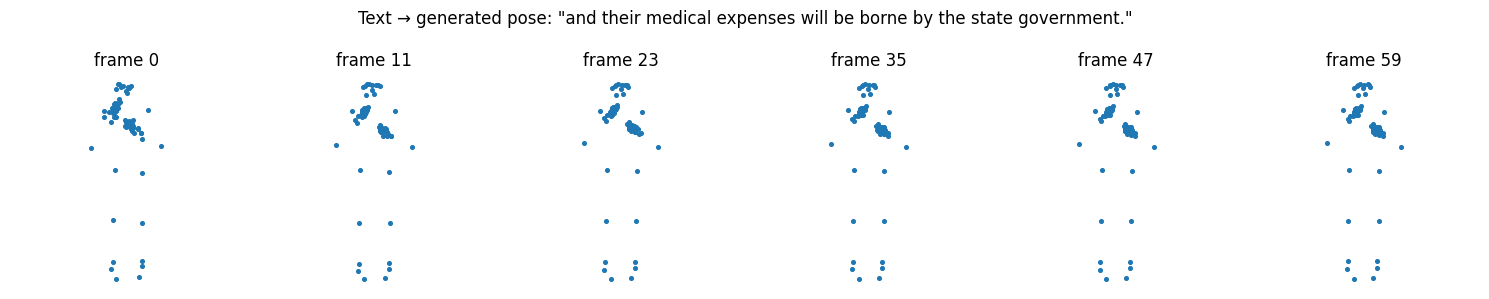

In [33]:
import matplotlib.pyplot as plt

sample_text = df_test.iloc[0]["text"]
generated = generate_pose(sample_text)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, fi in zip(axes, np.linspace(0, len(generated)-1, 6).astype(int)):
    pts = generated[fi].reshape(543, 3)
    # Show pose + hands; face is omitted from the static plot for readability.
    visible = np.concatenate([pts[:33], pts[501:543]], axis=0)
    ax.scatter(visible[:,0], -visible[:,1], s=7)
    ax.set_title(f"frame {fi}")
    ax.axis("equal")
    ax.axis("off")
fig.suptitle(f'Text → generated pose: "{sample_text}"')
plt.tight_layout()
plt.show()


## 15. Real round-trip sanity check

The previous notebook's round-trip cell was conceptually incomplete: it generated a pose, but then fed the **ground-truth pose from the original dataset row** into Sign → Text.

This cell fixes that. It generates a pose from text, then feeds the **generated pose** into the Sign → Text Transformer.

This is a model-level round trip, not a claim of live webcam performance.

In [34]:
@torch.no_grad()
def sign_text_from_pose_array(pose_array):
    # pose_array is normalized 543-landmark data.
    feature = pose_array[:, FULL_FEATURE_MASK]
    true_len = min(len(feature), MAX_FRAMES)
    feature = resize_sequence(feature, MAX_FRAMES)
    frames = torch.from_numpy(np.ascontiguousarray(feature)).float()
    return greedy_transformer(transformer_full, frames, true_len)

roundtrip_text = df_test.iloc[0]["text"]
roundtrip_gloss = text_to_naive_gloss(roundtrip_text)
roundtrip_pose = generate_pose(roundtrip_text)
roundtrip_recovered = sign_text_from_pose_array(roundtrip_pose)

print("Original text :", roundtrip_text)
print("Gloss         :", roundtrip_gloss)
print("Generated pose:", roundtrip_pose.shape)
print("Recovered text:", roundtrip_recovered)


Original text : and their medical expenses will be borne by the state government.
Gloss         : their medical expenses will be borne state government.
Generated pose: (60, 1629)
Recovered text: the police were not be given to the police


## 16. Latency harness

These are **model-only** timings. They are not end-to-end browser → WebSocket → backend → model timings and must not be presented as the project's final system latency.

In [35]:
def measure_ms(fn, *args, runs=10):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    times = []
    for _ in range(runs):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn(*args)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(times)), float(np.std(times))

sample_frames, sample_len, _ = test_ds_full[0]
s2t_mean, s2t_std = measure_ms(greedy_transformer, transformer_full, sample_frames, sample_len)
t2p_mean, t2p_std = measure_ms(generate_pose, df_test.iloc[0]["text"])

print(f"Sign → Text Transformer: {s2t_mean:.2f} ± {s2t_std:.2f} ms")
print(f"Text → Pose generator : {t2p_mean:.2f} ± {t2p_std:.2f} ms")
print("Target-hardware end-to-end latency still requires the eventual client/backend implementation.")


Sign → Text Transformer: 55.52 ± 0.44 ms
Text → Pose generator : 15.60 ± 0.34 ms
Target-hardware end-to-end latency still requires the eventual client/backend implementation.


In [36]:
# 16a. Record runtime and round-trip observations.
knowledge_metric("Runtime", "sign_to_text_latency_ms_mean", s2t_mean, "inference")
knowledge_metric("Runtime", "sign_to_text_latency_ms_std", s2t_std, "inference")
knowledge_metric("Runtime", "text_to_pose_latency_ms_mean", t2p_mean, "inference")
knowledge_metric("Runtime", "text_to_pose_latency_ms_std", t2p_std, "inference")

knowledge_observation("round_trip", {
    "original_text": roundtrip_text,
    "gloss": roundtrip_gloss,
    "recovered_text": roundtrip_recovered,
    "generated_pose_shape": list(roundtrip_pose.shape),
})
knowledge_observation("hardware", {
    "device": str(DEVICE),
    "gpu_count": int(torch.cuda.device_count()),
    "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
})
print("Runtime and round-trip observations recorded.")


Runtime and round-trip observations recorded.


## 17. Automatic go / no-go report

This section does not pretend a failing experiment is a success. It tells you exactly what the current run established.

**Interpretation rules:**

- GRU training loss should decrease without exploding while validation remains finite.
- Transformer should beat the trivial baseline on at least the primary translation metric(s) before being described as successful.
- Face ablation is interpretable because the mask is verified from the actual pose header.
- Text → Pose generation should be compared against retrieval rather than judged by MSE alone.
- The round-trip result is qualitative evidence only; it is not an independent benchmark.

In [37]:
def better(a, b, metric):
    return a[metric] < b[metric] if metric == "WER" else a[metric] > b[metric]

gru_decreased = len(gru_history) >= 2 and gru_history[-1][1] < gru_history[0][1]
transformer_beats_trivial = (
    better(results_s2t["Transformer (full)"], results_s2t["Trivial baseline"], "WER")
    or better(results_s2t["Transformer (full)"], results_s2t["Trivial baseline"], "BLEU")
)

print("=== SignSage Phase-0 status ===")
print("Data backend:", DATA_MODE)
print("Run mode:", RUN_MODE)
print("Device:", DEVICE)
print("GRU training loss decreased:", gru_decreased)
print("Transformer beats trivial on at least one headline metric:", transformer_beats_trivial)
print("Face ablation available:", len(NOFACE_FEATURE_MASK) < len(FULL_FEATURE_MASK))
print("Text→Pose retrieval DTW:", round(float(np.mean(retrieval_dtw)), 3))
print("Text→Pose generative DTW:", round(float(np.mean(generative_dtw)), 3))
print("Round-trip recovered text:", roundtrip_recovered)

if not transformer_beats_trivial:
    print("\nNO-GO: do not claim successful Sign→Text translation yet. This bounded run established pipeline execution only; increase the sample/epoch budget after diagnosing the result.")
else:
    print("\nGO CANDIDATE: Transformer shows measurable signal relative to the trivial baseline. Repeat at larger scale before treating it as a thesis result.")
    if min(gru_unique_frac, tf_unique_frac) < 0.3:
        print("CAVEAT: output diversity is low (see Section 10 above) -- this GO CANDIDATE may reflect\n"
              "         the model collapsing to a near-fixed output rather than genuine translation. Treat\n"
              "         this specifically as a data-scale/task-difficulty finding (see PHASES.md), not as\n"
              "         evidence the architecture works, until diversity improves at a larger scale.")

_t2p_motion_collapsed = bool(np.isfinite(_gen_motion_ratio) and _gen_motion_ratio < 0.3)

if np.mean(generative_dtw) > np.mean(retrieval_dtw):
    print("Text→Pose: generation is currently worse than retrieval on DTW; do not claim generative competitiveness yet.")
elif _t2p_motion_collapsed:
    print(f"Text→Pose: generation beats retrieval on DTW/MSE, BUT motion-energy analysis\n"
          f"(Section 13) shows generated motion is only {_gen_motion_ratio:.0%} of ground-truth\n"
          "motion -- consistent with a near-static/average-pose collapse rather than genuine\n"
          "sign motion. Do NOT report the DTW/MSE win alone as evidence of successful pose\n"
          "generation; inspect the pose visualization (Section 14) before drawing any\n"
          "conclusion here.")
else:
    print("Text→Pose: generation is competitive with retrieval on DTW, and motion energy is\n"
          "reasonably close to ground truth -- a more credible (though still bounded-run-scale)\n"
          "positive signal.")


# Knowledge-repository summary values.
knowledge_observation("go_no_go", {
    "gru_training_loss_decreased": bool(gru_decreased),
    "transformer_beats_trivial": bool(transformer_beats_trivial),
    "face_ablation_available": bool(len(NOFACE_FEATURE_MASK) < len(FULL_FEATURE_MASK)),
    "retrieval_dtw_mean": float(np.mean(retrieval_dtw)),
    "generative_dtw_mean": float(np.mean(generative_dtw)),
    "text_to_pose_motion_collapsed": _t2p_motion_collapsed,
    "phase_0_status": (
        "GO-CANDIDATE" if transformer_beats_trivial else "NO-GO"
    ),
    "output_diversity_flagged": bool(min(gru_unique_frac, tf_unique_frac) < 0.3),
})


=== SignSage Phase-0 status ===
Data backend: kaggle
Run mode: kaggle
Device: cuda
GRU training loss decreased: True
Transformer beats trivial on at least one headline metric: True
Face ablation available: True
Text→Pose retrieval DTW: 591.847
Text→Pose generative DTW: 378.806
Round-trip recovered text: the police were not be given to the police

GO CANDIDATE: Transformer shows measurable signal relative to the trivial baseline. Repeat at larger scale before treating it as a thesis result.
CAVEAT: output diversity is low (see Section 10 above) -- this GO CANDIDATE may reflect
         the model collapsing to a near-fixed output rather than genuine translation. Treat
         this specifically as a data-scale/task-difficulty finding (see PHASES.md), not as
         evidence the architecture works, until diversity improves at a larger scale.
Text→Pose: generation beats retrieval on DTW/MSE, BUT motion-energy analysis
(Section 13) shows generated motion is only 7% of ground-truth
motion -

In [38]:
# 18. Finalize and export the project knowledge repository
#
# This is the hand-off point from Kaggle experimentation to application engineering.
# Copy the entire `signsage_outputs/` directory into the SignSage project later.
#
# SQLite is the queryable research record.
# JSON is the portable snapshot a backend can load without SQL.

def _history_to_dict(history):
    return [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(val)}
        for epoch, train, val in history
    ]

manifest = {
    "project": "SignSage",
    "repository_version": 1,
    "run_id": RUN_ID,
    "started_at": RUN_STARTED_AT,
    "completed_at": datetime.now(timezone.utc).isoformat(),
    "environment": {
        "data_mode": DATA_MODE,
        "run_mode": RUN_MODE,
        "device": str(DEVICE),
        "gpu_count": int(torch.cuda.device_count()),
        "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
        "python_executable": os.sys.executable,
        "seed": SEED,
    },
    "dataset": {
        "name": "iSign v1.1",
        "csv_path": str(CSV_PATH),
        "csv_rows": int(len(df)),
        "unique_video_ids": int(df["video_id"].nunique()),
        "selected_rows": int(len(df_train) + len(df_val) + len(df_test)),
        "pose_source": pose_source,
    },
    "split": {
        "train_rows": int(len(df_train)),
        "val_rows": int(len(df_val)),
        "test_rows": int(len(df_test)),
        "train_videos": train_videos,
        "val_videos": val_videos,
        "test_videos": test_videos,
        "leakage_free": bool(leakage_free),
    },
    "configuration": {
        "max_tokens": MAX_TOKENS,
        "max_frames": MAX_FRAMES,
        "pose_output_frames": POSE_OUTPUT_FRAMES,
        "batch_size": BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS,
        "amp": bool(USE_AMP),
        "full_feature_dim": int(LANDMARK_DIM),
        "no_face_feature_dim": int(NOFACE_DIM),
        "vocab_size": int(len(vocab)),
        "use_llm_gloss": bool(USE_LLM_GLOSS),
    },
    "models": {
        "gru": {
            "checkpoint": str(CHECKPOINT_DIR / "signsage_gru_best.pt"),
            "history": _history_to_dict(gru_history),
        },
        "transformer_full": {
            "checkpoint": str(CHECKPOINT_DIR / "signsage_transformer_full.pt"),
            "history": _history_to_dict(transformer_full_history),
        },
        "transformer_no_face": {
            "checkpoint": str(CHECKPOINT_DIR / "signsage_transformer_noface.pt"),
            "history": _history_to_dict(transformer_noface_history),
        },
        "text_to_pose_gru": {
            "checkpoint": str(CHECKPOINT_DIR / "signsage_text_to_pose_best.pt"),
            "history": _history_to_dict(pose_history),
        },
    },
    "evaluation": {
        "sign_to_text": results_s2t,
        "text_to_pose": t2p_metrics,
        "runtime_ms": {
            "sign_to_text_mean": float(s2t_mean),
            "sign_to_text_std": float(s2t_std),
            "text_to_pose_mean": float(t2p_mean),
            "text_to_pose_std": float(t2p_std),
        },
        "round_trip": {
            "original_text": roundtrip_text,
            "gloss": roundtrip_gloss,
            "recovered_text": roundtrip_recovered,
        },
    },
    "status": {
        "transformer_beats_trivial": bool(transformer_beats_trivial),
        "phase_0_status": "GO-CANDIDATE" if transformer_beats_trivial else "NO-GO",
        "warning": "A bounded Kaggle run is not automatically a thesis-quality final result.",
    },
    "artifacts": {
        "sqlite_knowledge_base": str(KNOWLEDGE_DB_PATH),
        "json_manifest": str(KNOWLEDGE_JSON_PATH),
        "checkpoints_dir": str(CHECKPOINT_DIR),
    },
}

with open(KNOWLEDGE_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

knowledge_artifact(
    "knowledge_sqlite",
    "sqlite",
    KNOWLEDGE_DB_PATH,
    "Structured project knowledge repository: dataset, splits, experiments, metrics, artifacts, observations.",
)
knowledge_artifact(
    "knowledge_manifest",
    "json",
    KNOWLEDGE_JSON_PATH,
    "Portable JSON snapshot of the experiment and deployment-relevant metadata.",
)

# Mark run complete.
conn = _sql_connect()
conn.execute(
    "UPDATE runs SET completed_at = ? WHERE run_id = ?",
    (manifest["completed_at"], RUN_ID),
)
conn.commit()
conn.close()

print("==================================================")
print("SignSage knowledge repository finalized.")
print("SQLite :", KNOWLEDGE_DB_PATH)
print("JSON   :", KNOWLEDGE_JSON_PATH)
print("Models :", CHECKPOINT_DIR)
print("Status :", manifest["status"]["phase_0_status"])
print("==================================================")


SignSage knowledge repository finalized.
SQLite : /kaggle/working/signsage_outputs/signsage_knowledge.db
JSON   : /kaggle/working/signsage_outputs/signsage_knowledge_manifest.json
Models : /kaggle/working/signsage_outputs/checkpoints
Status : GO-CANDIDATE


## 19. Kaggle → SignSage project hand-off

After the run completes, the important output is the directory:

```text
/kaggle/working/signsage_outputs/
├── checkpoints/
│   ├── signsage_gru_best.pt
│   ├── signsage_transformer_full.pt
│   ├── signsage_transformer_noface.pt
│   └── signsage_text_to_pose_best.pt
├── reports/
│   └── token_vocabulary.json
├── signsage_knowledge.db
└── signsage_knowledge_manifest.json
```

Copy these outputs into the main SignSage project on the development machine.

The later full-stack application should **not execute this training notebook per request**. Instead:

```text
Frontend
   ↓
Backend / API
   ↓
Trained model checkpoints
   ↓
SQLite knowledge repository + JSON metadata
   ↓
Inference result
```

The notebook therefore acts as the **model factory + reproducibility record**. The backend becomes the **serving layer**.

For an M.Tech demonstration, the SQLite repository provides a concrete, queryable record of the AI/ML lifecycle rather than merely presenting a `.pt` model file with no experimental context.


In [39]:
# 20. Final artifact inventory
artifact_paths = sorted([
    p for p in OUTPUT_DIR.rglob("*")
    if p.is_file()
])

print(f"Artifacts written: {len(artifact_paths)}")
for p in artifact_paths:
    size_mb = p.stat().st_size / (1024**2)
    print(f"{p.relative_to(OUTPUT_DIR)} — {size_mb:.2f} MB")


Artifacts written: 7
checkpoints/signsage_gru_best.pt — 34.43 MB
checkpoints/signsage_text_to_pose_best.pt — 18.41 MB
checkpoints/signsage_transformer_full.pt — 32.32 MB
checkpoints/signsage_transformer_noface.pt — 31.29 MB
reports/token_vocabulary.json — 0.35 MB
signsage_knowledge.db — 0.05 MB
signsage_knowledge_manifest.json — 0.01 MB
